In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
from sklearn.metrics import mean_squared_error
color_pal = sns.color_palette()
plt.style.use('fivethirtyeight')

In [2]:
Housing_df = pd.read_excel('/Users/keyan/Downloads/HousingPermitsandPopulationGrowth.xlsx')
pd.set_option('display.max_columns', None)

Housing_df.head(14)

,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Previous_Population,Population_Growth,Corresponding_Population_Growth,Population_Growth_Rate,Lag_Total_Permits_per_1000,Lag_Single_Family_Permits_per_1000,Lag_3_or_More_Unit_Permits_per_1000,Lag_Total_Multifamily_Permits_per_1000,Lag_Median_House_Value,Lag_Median_Rent,Lag_Median_Household_Income,Total_Permits_Growth_Rate,Single_Family_Permits_Growth_Rate,Median_House_Value_Growth_Rate,Median_Rent_Growth_Rate,Median_Household_Income_Growth_Rate
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,NaN,NaN,-0.499162,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,25643.0,-0.499162,-0.501666,-0.49916,0.74094,0.74094,0.00000,0.00000,85900.0,539.0,33143.0,69.266067,69.266067,3.72526,3.33952,4.60731
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,25515.0,-0.501666,-0.606610,-0.50167,1.25416,1.25416,0.00000,0.00000,89100.0,557.0,34670.0,-27.762008,-27.762008,1.34680,6.46320,1.14508
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,25387.0,-0.606610,-0.527088,-0.60661,0.90598,0.90598,0.00000,0.00000,90300.0,593.0,35067.0,22.481732,22.481732,0.99668,6.07083,2.50948
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.0,139.0,491.193,

In [3]:
Housing_df.loc[
    Housing_df["Year"] == 2020,
    "Corresponding_Population_Growth"
] = np.nan

Housing_df.head(14)

,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Previous_Population,Population_Growth,Corresponding_Population_Growth,Population_Growth_Rate,Lag_Total_Permits_per_1000,Lag_Single_Family_Permits_per_1000,Lag_3_or_More_Unit_Permits_per_1000,Lag_Total_Multifamily_Permits_per_1000,Lag_Median_House_Value,Lag_Median_Rent,Lag_Median_Household_Income,Total_Permits_Growth_Rate,Single_Family_Permits_Growth_Rate,Median_House_Value_Growth_Rate,Median_Rent_Growth_Rate,Median_Household_Income_Growth_Rate
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,NaN,NaN,-0.499162,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,25643.0,-0.499162,-0.501666,-0.49916,0.74094,0.74094,0.00000,0.00000,85900.0,539.0,33143.0,69.266067,69.266067,3.72526,3.33952,4.60731
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,25515.0,-0.501666,-0.606610,-0.50167,1.25416,1.25416,0.00000,0.00000,89100.0,557.0,34670.0,-27.762008,-27.762008,1.34680,6.46320,1.14508
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.000000,0.00000,0.00000,0.0,0.000000,0.00000,0.00000,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,25387.0,-0.606610,-0.527088,-0.60661,0.90598,0.90598,0.00000,0.00000,90300.0,593.0,35067.0,22.481732,22.481732,0.99668,6.07083,2.50948
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.0,139.0,491.193,

In [4]:
Housing_df = Housing_df[Housing_df["Total_Population"] >= 2500]


Housing_df = Housing_df[
    Housing_df["Total_Multifamily_Permits_per_1000"] <= 20
]

print(Housing_df.shape[0])

Housing_df.head(14)


#The first line gets rid of counties with a population of under 2500 because they tend to be very noisy, while the 2nd one gets rid of 
#counties giving more than 20 multifamily permits per 1000, as it forms a sample of roughly 30 observations which significantly muddy the 
#effects of multifamily permitting on population growth

38990


,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Previous_Population,Population_Growth,Corresponding_Population_Growth,Population_Growth_Rate,Lag_Total_Permits_per_1000,Lag_Single_Family_Permits_per_1000,Lag_3_or_More_Unit_Permits_per_1000,Lag_Total_Multifamily_Permits_per_1000,Lag_Median_House_Value,Lag_Median_Rent,Lag_Median_Household_Income,Total_Permits_Growth_Rate,Single_Family_Permits_Growth_Rate,Median_House_Value_Growth_Rate,Median_Rent_Growth_Rate,Median_Household_Income_Growth_Rate
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.000000,0.00000,0.00000,0.00000,0.000000,0.00000,0.00000,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,NaN,NaN,-0.499162,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.000000,0.00000,0.00000,0.00000,0.000000,0.00000,0.00000,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,25643.0,-0.499162,-0.501666,-0.49916,0.74094,0.74094,0.00000,0.00000,85900.0,539.0,33143.0,69.266067,69.266067,3.72526,3.33952,4.60731
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.000000,0.00000,0.00000,0.00000,0.000000,0.00000,0.00000,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,25515.0,-0.501666,-0.606610,-0.50167,1.25416,1.25416,0.00000,0.00000,89100.0,557.0,34670.0,-27.762008,-27.762008,1.34680,6.46320,1.14508
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.000000,0.00000,0.00000,0.00000,0.000000,0.00000,0.00000,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,25387.0,-0.606610,-0.527088,-0.60661,0.90598,0.90598,0.00000,0.00000,90300.0,593.0,35067.0,22.481732,22.481732,0.99668,6.07083,2.50948
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.

In [5]:
outside_range = (
    (Housing_df['Corresponding_Population_Growth'] < -5) |
    (Housing_df['Corresponding_Population_Growth'] > 8)
)

#This function takes a look at counties with growth levels between -5% to 8%, and the lines below say
#a. how many counties are outside the range
#b. how many counties have a population growth rate of less than -5% specifically
#c. how many counties have a population growth rate of more than 8% specifically

print("Outside range:", outside_range.sum())

print("Below -5%:", (Housing_df['Corresponding_Population_Growth'] < -5).sum())
print("Above 8%:", (Housing_df['Corresponding_Population_Growth'] > 8).sum())



outside_range_2 = (
    (Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'] < -12.5) |
    (Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'] > 15)
)


print("\nOutside range:", outside_range_2.sum())

print("Below -12.5%:", (Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'] < -12.5).sum())
print("Above 15%:", (Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'] > 15).sum())

Outside range: 40
Below -5%: 26
Above 8%: 14

Outside range: 164
Below -12.5%: 122
Above 15%: 42


In [6]:
Housing_df = Housing_df[Housing_df['Corresponding_Population_Growth'].between(-5, 8)]

Housing_df.head(14)

Housing_df = Housing_df[
    Housing_df['Corresponding_Growth_In_Occupied_Housing_Units'].between(-12.5, 15)
]

In [8]:
columns_to_remove = [
    "Previous_Population",
    "Population_Growth",
    "Population_Growth_Rate",
    "Lag_Total_Permits_per_1000",
    "Lag_Single_Family_Permits_per_1000",
    "Lag_3_or_More_Unit_Permits_per_1000",
    "Lag_Total_Multifamily_Permits_per_1000",
    "Lag_Median_House_Value",
    "Lag_Median_Rent",
    "Lag_Median_Household_Income",
    "Total_Permits_Growth_Rate",
    "Single_Family_Permits_Growth_Rate",
    "Median_House_Value_Growth_Rate",
    "Median_Rent_Growth_Rate",
    "Median_Household_Income_Growth_Rate"
]

Housing_df = Housing_df.drop(columns=columns_to_remove)

Housing_df.head(14)

#This takes some extraneous variables and removes them from the table to make it more lean

,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Corresponding_Population_Growth
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,-0.499162
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,-0.501666
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,-0.606610
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,-0.527088
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.0,139.0,491.193,0.163347,1.63347,0.163347,1.63347,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,78.17884,46.03393,22.38247,68.95219,28.81673,0.00398,0.55378,49.01316,51.100077,-0.410359
5,Abbeville County: South Carolina,2015,24997,287,1.148138,-0.162205,78.1,12.3,26.0,26.0,0.0,0.0,0.0,0.0,88300.0,77.0,861.0,562.0,382.965956,9573,-1.835521,-0.773007,7571.0,34799.0,43.3,18.8,20248.0,9294.0,5471.0,17229.0,6986.0,0.0,301.0,491.193,0.104012,1.04012,0.104012,1.04012,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,79.08702,45.90083,21.88663,68.92427,27.94735,0.00000,1.20414,46.85315,50.890383,-0.184022
6,Abbeville County: South Carolina,2016,24951,246,0.985932,-0.054030,78.3,13.7,39.0,39.0,0.0,0.0,0.0,0.0,88100.0,107.0,911.0,611.0,380.706184,9499,-0.773007,-1.126434,7372.0,34652.0,43.6,19.6,20243.0,9624.0,5230.0,17196.0,6777.0,77.0,326.0,491.193,0.156306,1.56306,0.156306,1.56306

In [9]:
Housing_df['Housing_Permit_Percentile'] = (Housing_df['Total_Permits_per_1000'].rank(pct=True) * 100)

Housing_df.head(14)

,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Corresponding_Population_Growth,Housing_Permit_Percentile
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,-0.499162,32.074421
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,-0.501666,45.262366
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,-0.606610,36.380348
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,-0.527088,41.757186
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.0,139.0,491.193,0.163347,1.63347,0.163347,1.63347,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,78.17884,46.03393,22.38247,68.95219,28.81673,0.00398,0.55378,49.01316,51.100077,-0.410359,53.551136
5,Abbeville County: South Carolina,2015,24997,287,1.148138,-0.162205,78.1,12.3,26.0,26.0,0.0,0.0,0.0,0.0,88300.0,77.0,861.0,562.0,382.965956,9573,-1.835521,-0.773007,7571.0,34799.0,43.3,18.8,20248.0,9294.0,5471.0,17229.0,6986.0,0.0,301.0,491.193,0.104012,1.04012,0.104012,1.04012,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,79.08702,45.90083,21.88663,68.92427,27.94735,0.00000,1.20414,46.85315,50.890383,-0.184022,39.969084
6,Abbeville County: South Carolina,2016,24951,246,0.985932,-0.054030,78.3,13.7,39.0,39.0,0.0,0.0,0.0,0.0,88100.0,107.0,911.0,611.0,380.706184,9499,-0.773007,-1.126434,7372.0,34652.0,43.6,19.6,202

In [10]:
Housing_df['Housing_Permit_Q1'] = (
    Housing_df['Total_Permits_per_1000'] <=
    Housing_df['Total_Permits_per_1000'].quantile(0.25)
).astype(int)

Housing_df['Housing_Permit_Q2'] = (
    (Housing_df['Total_Permits_per_1000'] >
     Housing_df['Total_Permits_per_1000'].quantile(0.25)) &
    (Housing_df['Total_Permits_per_1000'] <=
     Housing_df['Total_Permits_per_1000'].quantile(0.50))
).astype(int)

Housing_df['Housing_Permit_Q3'] = (
    (Housing_df['Total_Permits_per_1000'] >
     Housing_df['Total_Permits_per_1000'].quantile(0.50)) &
    (Housing_df['Total_Permits_per_1000'] <=
     Housing_df['Total_Permits_per_1000'].quantile(0.75))
).astype(int)

Housing_df['Housing_Permit_Q4'] = (
    Housing_df['Total_Permits_per_1000'] >
    Housing_df['Total_Permits_per_1000'].quantile(0.75)
).astype(int)


Housing_df.head(15)

,County_State_Name,Year,Total_Population,Foreign_Born_Population,Foreign_Born_Pct,Change_In_Foreign_Born_Share,HS_Grad_or_Higher,Bach_Degree_or_Higher,Total_Permits,Single_Family_Permits,Tot_Multifamily_Permits,2_Unit_Permits,3_or_4_Unit_Permits,5_or_More_Unit_Permits,Median_House_Value,Total_Paying_30_to_34.9_Pct,Total_Paying_Over_35_Pct,Median_Rent,Housing_Units_Per_1000,Occupied_Housing_Units,Growth_In_Occupied_Housing_Units,Corresponding_Growth_In_Occupied_Housing_Units,Owner_Occupied,Median_Household_Income,Median_Age_Years,Pct_Age_65_or_above,Working_Age_Population,Total_Number_Employed,Number_In_Poverty,White_Population,Black_Population,Asian_Population,Hispanic_Population,Land_Area_Sq_Miles,Total_Permits_per_100,Total_Permits_per_1000,Single_Family_Permits_per_100,Single_Family_Permits_per_1000,Total_Multifamily_Permits_per_100,Total_Multifamily_Permits_per_1000,2_Unit_Permits_per_1000,3_or_4_Unit_Permits_per_1000,5_or_More_Unit_Permits_per_100,5_or_More_Unit_Permits_per_1000,3_or_More_Unit_Permits_per_1000,Homeownership_Rate,Employment_Population_Ratio,Poverty_Rate,White_Pct,Black_Pct,Asian_Pct,Hispanic_Pct,Rent_Burden_Over_30_Pct,Population_Density,Corresponding_Population_Growth,Housing_Permit_Percentile,Housing_Permit_Q1,Housing_Permit_Q2,Housing_Permit_Q3,Housing_Permit_Q4
0,Abbeville County: South Carolina,2010,25643,369,1.438989,0.022896,76.8,15.3,19.0,19.0,0.0,0.0,0.0,0.0,85900.0,216.0,947.0,539.0,385.095348,9875,NaN,-0.648101,7642.0,33143.0,41.1,16.0,20314.0,9993.0,5084.0,17741.0,7281.0,49.0,268.0,491.193,0.074094,0.74094,0.074094,0.74094,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.38734,49.19268,19.82607,69.18457,28.39371,0.19109,1.04512,52.08240,52.205549,-0.499162,32.074421,0,1,0,0
1,Abbeville County: South Carolina,2011,25515,373,1.461885,-0.315629,77.1,13.9,32.0,32.0,0.0,0.0,0.0,0.0,89100.0,171.0,912.0,557.0,384.518910,9811,-0.648101,0.682907,7638.0,34670.0,41.9,16.3,20268.0,9814.0,4842.0,17630.0,7493.0,22.0,88.0,491.193,0.125416,1.25416,0.125416,1.25416,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.85139,48.42116,18.97707,69.09661,29.36704,0.08622,0.34490,49.83893,51.944958,-0.501666,45.262366,0,1,0,0
2,Abbeville County: South Carolina,2012,25387,291,1.146256,-0.127748,75.7,12.5,23.0,23.0,0.0,0.0,0.0,0.0,90300.0,221.0,805.0,593.0,389.096782,9878,0.682907,-0.698522,7675.0,35067.0,42.4,16.9,20266.0,9599.0,5101.0,17523.0,7144.0,15.0,267.0,491.193,0.090598,0.90598,0.090598,0.90598,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,77.69791,47.36504,20.09296,69.02352,28.14039,0.05909,1.05172,46.57286,51.684368,-0.606610,36.380348,0,1,0,0
3,Abbeville County: South Carolina,2013,25233,257,1.018508,0.101014,76.8,12.2,28.0,28.0,0.0,0.0,0.0,0.0,91200.0,98.0,910.0,629.0,388.736971,9809,-0.698522,-0.581099,7491.0,35947.0,42.8,17.3,20283.0,9341.0,5272.0,17421.0,7308.0,14.0,144.0,491.193,0.110966,1.10966,0.110966,1.10966,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,76.36864,46.05335,20.89327,69.04054,28.96207,0.05548,0.57068,43.48576,51.370846,-0.527088,41.757186,0,1,0,0
4,Abbeville County: South Carolina,2014,25100,281,1.119522,0.028616,77.7,12.3,41.0,41.0,0.0,0.0,0.0,0.0,89000.0,109.0,934.0,583.0,388.525896,9752,-0.581099,-1.835521,7624.0,35409.0,43.1,17.9,20335.0,9361.0,5618.0,17307.0,7233.0,1.0,139.0,491.193,0.163347,1.63347,0.163347,1.63347,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,78.17884,46.03393,22.38247,68.95219,28.81673,0.00398,0.55378,49.01316,51.100077,-0.410359,53.551136,0,0,1,0
5,Abbeville County: South Carolina,2015,24997,287,1.148138,-0.162205,78.1,12.3,26.0,26.0,0.0,0.0,0.0,0.0,88300.0,77.0,861.0,562.0,382.965956,9573,-1.835521,-0.773007,7571.0,34799.0,43.3,18.8,20248.0,9294.0,5471.0,17229.0,6986.0,0.0,301.0,491.193,0.104012,1.04012,0.104012,1.04012,0.000000,0.00000,0.00000,0.00000,0.0,0.0,0.00000,79.08702,45.90083,21.88663,68.92427,27.94735,0.00000,1.20414,46.85315,50.890383,-0.184022,39.969084,0,1,0,0
6,Abbeville County: South Carolina,2016,24951,246,0.985932,-0.054030,78.3,1

In [11]:
Housing_df['log_Total_Population'] = np.log1p(Housing_df["Total_Population"])
Housing_df['log_Median_House_Val'] = np.log1p(Housing_df["Median_House_Value"])
Housing_df['log_Foreign_Born_Pct'] = np.log1p(Housing_df["Foreign_Born_Pct"])
Housing_df['log_Population_Density'] = np.log1p(Housing_df["Population_Density"])

Housing_df["recip_Rent"] = (1 / Housing_df["Median_Rent"])
Housing_df["recip_Median_Income"] = (1 / Housing_df["Median_Household_Income"])

Housing_df["Black_Pct_squared"] = (Housing_df["Black_Pct"]**2)
Housing_df["Black_Pct_cubed"] = (Housing_df["Black_Pct"]**3)


Housing_df['White_Pct_squared'] = Housing_df['White_Pct'] ** 2
Housing_df['log_Foreign_Born_Pct'] = np.log1p(Housing_df['Foreign_Born_Pct'])
Housing_df['log_Population_Density'] = np.log1p(Housing_df['Population_Density'])

Housing_df['Permits_x_Housing_Growth'] = (
    Housing_df['Total_Permits_per_1000'] *
    Housing_df['Corresponding_Growth_In_Occupied_Housing_Units']
)

Housing_df['Permits_x_House_Value'] = (
    Housing_df['Total_Permits_per_1000'] *
    Housing_df['Median_House_Value']
)

In [12]:
Housing_df = Housing_df.sort_values(
    ["County_State_Name", "Year"]
)

Housing_df["Previous_Corresponding_Growth"] = (
    Housing_df
    .groupby("County_State_Name")["Corresponding_Population_Growth"]
    .shift(1)
)

#Housing_df["Previous_2_Corresponding_Growth"] = (
#    Housing_df
#    .groupby("County_State_Name")["Corresponding_Population_Growth"]
#    .shift(2)
#)

In [13]:
predictors = [
    'Previous_Corresponding_Growth',
    #'Previous_2_Corresponding_Growth',
    'Corresponding_Growth_In_Occupied_Housing_Units',
    'Total_Permits_per_1000',
    'Permits_x_Housing_Growth',
    'Permits_x_House_Value',
    'Homeownership_Rate',
    'Employment_Population_Ratio',
    'White_Pct',
    'Change_In_Foreign_Born_Share',
    'White_Pct_squared',
    'Rent_Burden_Over_30_Pct',
    'Median_House_Value',
    'Median_Age_Years',
    'log_Foreign_Born_Pct',
    'log_Population_Density',
    'recip_Median_Income',
    'Black_Pct',
    'Black_Pct_squared',
    'Black_Pct_cubed'
]

In [14]:
def get_quartile_data(Housing_df, quartile_column):

    current = Housing_df[
        ["County_State_Name", "Year", quartile_column]
    ].copy()

    next_year = Housing_df[
        ["County_State_Name", "Year", quartile_column]
    ].copy()

    current = current.rename(
        columns={quartile_column: "Current_Quartile"}
    )

    next_year = next_year.rename(
        columns={
            "Year": "Next_Year",
            quartile_column: "Next_Quartile"
        }
    )

    transition = current.merge(
        next_year,
        on="County_State_Name",
        how="inner"
    )


    valid_transitions = (
        ((transition["Year"] <= 2019) &
         (transition["Next_Year"] == transition["Year"] + 1))
        |
        ((transition["Year"] >= 2021) &
         (transition["Next_Year"] == transition["Year"] + 1))
    )

    valid_counties = transition[
        valid_transitions &
        (transition["Current_Quartile"] == 1) &
        (transition["Next_Quartile"] == 1)
    ][
        ["County_State_Name", "Year"]
    ]

    quartile_data = Housing_df.merge(
        valid_counties,
        on=["County_State_Name", "Year"],
        how="inner"
    )

    return quartile_data

In [15]:
Q1_df = get_quartile_data(Housing_df, "Housing_Permit_Q1")
Q2_df = get_quartile_data(Housing_df, "Housing_Permit_Q2")
Q3_df = get_quartile_data(Housing_df, "Housing_Permit_Q3")
Q4_df = get_quartile_data(Housing_df, "Housing_Permit_Q4")

Q1_arima_data = Q1_df.groupby('Year')['Corresponding_Population_Growth'].mean()
Q2_arima_data = Q2_df.groupby('Year')['Corresponding_Population_Growth'].mean()
Q3_arima_data = Q3_df.groupby('Year')['Corresponding_Population_Growth'].mean()
Q4_arima_data = Q4_df.groupby('Year')['Corresponding_Population_Growth'].mean()

In [16]:
from statsmodels.tsa.stattools import adfuller

for name, data in {
    "Q1": Q1_arima_data,
    "Q2": Q2_arima_data,
    "Q3": Q3_arima_data,
    "Q4": Q4_arima_data
}.items():

    result = adfuller(data)

    print(name)
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    print()

Q1
ADF Statistic: -3.5846659923774733
p-value: 0.006061039253446606

Q2
ADF Statistic: -5.388576258295849
p-value: 3.5794507928522642e-06

Q3
ADF Statistic: -5.1333903744692515
p-value: 1.200611076356191e-05

Q4
ADF Statistic: -3.9931137946242123
p-value: 0.0014470018002010986



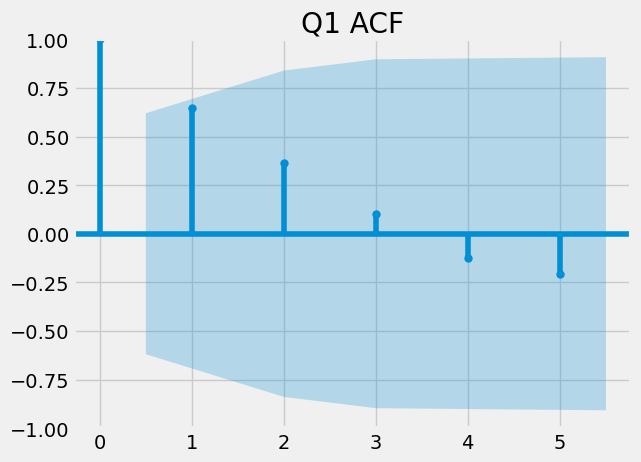

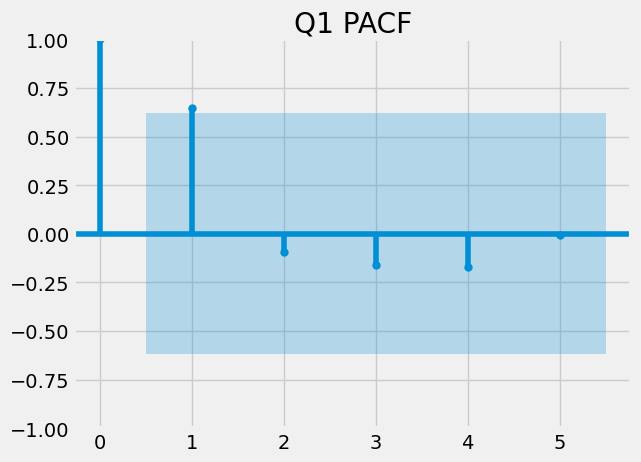

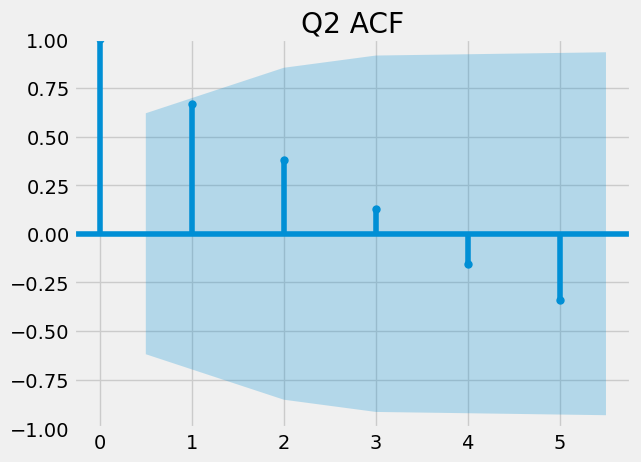

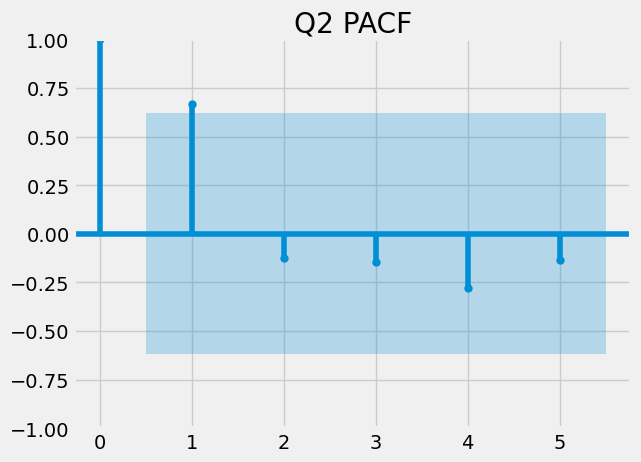

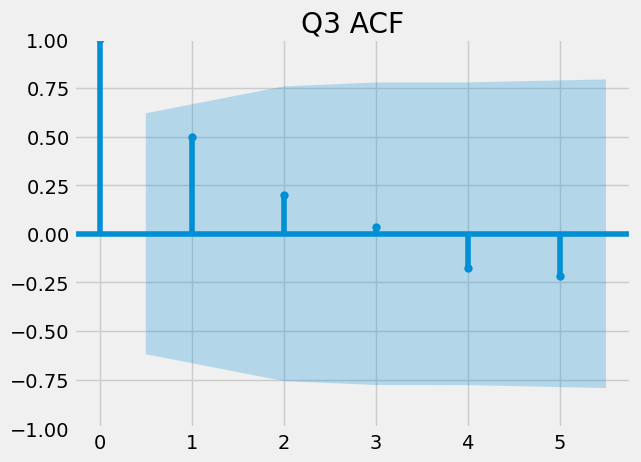

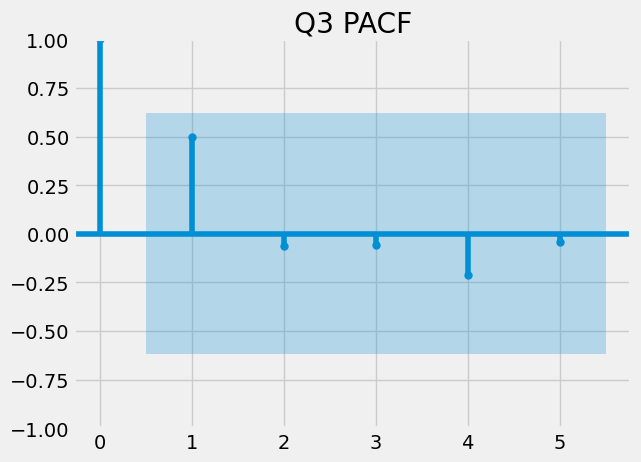

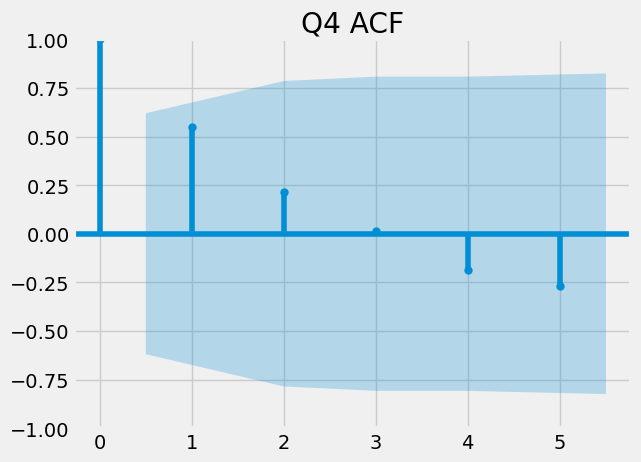

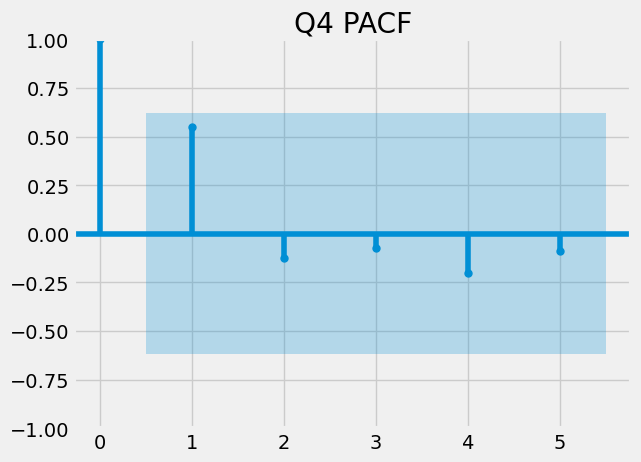

In [17]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Q1: d = 0
plot_acf(Q1_arima_data)
plt.title("Q1 ACF")
plt.show()

plot_pacf(Q1_arima_data)
plt.title("Q1 PACF")
plt.show()


# Q2: d = 0
plot_acf(Q2_arima_data)
plt.title("Q2 ACF")
plt.show()

plot_pacf(Q2_arima_data)
plt.title("Q2 PACF")
plt.show()


# Q3: d = 0
plot_acf(Q3_arima_data)
plt.title("Q3 ACF")
plt.show()

plot_pacf(Q3_arima_data)
plt.title("Q3 PACF")
plt.show()


# Q4: d = 0
plot_acf(Q4_arima_data)
plt.title("Q4 ACF")
plt.show()

plot_pacf(Q4_arima_data)
plt.title("Q4 PACF")
plt.show()

In [18]:
from statsmodels.tsa.arima.model import ARIMA
import itertools
import pandas as pd

def arima_grid_search(data, d):
    results = []

    for p, q in itertools.product(range(6), range(6)):
        try:
            model = ARIMA(data, order=(p, d, q)).fit()

            results.append({
                'p': p,
                'd': d,
                'q': q,
                'AIC': model.aic
            })

        except Exception:
            pass

    return pd.DataFrame(results).sort_values('AIC').reset_index(drop=True)

In [19]:
Q1_arima_results = arima_grid_search(Q1_arima_data, d=0)
Q2_arima_results = arima_grid_search(Q2_arima_data, d=0)
Q3_arima_results = arima_grid_search(Q3_arima_data, d=0)
Q4_arima_results = arima_grid_search(Q4_arima_data, d=0)

print("Q1:")
print(Q1_arima_results.head())

print("\nQ2:")
print(Q2_arima_results.head())

print("\nQ3:")
print(Q3_arima_results.head())

print("\nQ4:")
print(Q4_arima_results.head())

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a 

Q1:
   p  d  q        AIC
0  2  0  1 -13.161983
1  1  0  0 -12.091207
2  2  0  0 -12.025894
3  3  0  1 -11.351951
4  1  0  1 -11.301864

Q2:
   p  d  q        AIC
0  5  0  0 -24.742750
1  5  0  3 -23.228181
2  2  0  1 -21.876650
3  3  0  1 -19.487207
4  2  0  0 -19.204762

Q3:
   p  d  q       AIC
0  2  0  0 -9.053064
1  1  0  1 -8.167438
2  1  0  0 -7.447853
3  2  0  1 -7.053826
4  3  0  0 -7.053512

Q4:
   p  d  q        AIC
0  2  0  0 -12.403919
1  2  0  1 -11.410243
2  1  0  1 -10.960046
3  1  0  0 -10.710841
4  1  0  2 -10.705242


/Users/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for

In [20]:
Q1_arima_model = ARIMA(Q1_arima_data, order=(2, 0, 1)).fit()
Q2_arima_model = ARIMA(Q2_arima_data, order=(5, 0, 0)).fit()
Q3_arima_model = ARIMA(Q3_arima_data, order=(2, 0, 0)).fit()
Q4_arima_model = ARIMA(Q4_arima_data, order=(2, 0, 0)).fit()


print(Q1_arima_model.summary())
print(Q2_arima_model.summary())
print(Q3_arima_model.summary())
print(Q4_arima_model.summary())

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to 

                                      SARIMAX Results                                      
Dep. Variable:     Corresponding_Population_Growth   No. Observations:                   10
Model:                              ARIMA(2, 0, 1)   Log Likelihood                  11.581
Date:                             Tue, 20 Oct 2026   AIC                            -13.162
Time:                                     00:15:59   BIC                            -11.649
Sample:                                          0   HQIC                           -14.822
                                              - 10                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.2487      0.221     -1.123      0.261      -0.683       0.185
ar.L1          1.9081      

In [21]:
print(Q1_df.shape)
print(Q2_df.shape)
print(Q3_df.shape)
print(Q4_df.shape)

(6201, 72)
(4937, 72)
(4706, 72)
(5735, 72)


In [22]:
Q1_X = Q1_df[predictors]
Q1_y = Q1_df['Corresponding_Population_Growth']

Q2_X = Q2_df[predictors]
Q2_y = Q2_df['Corresponding_Population_Growth']

Q3_X = Q3_df[predictors]
Q3_y = Q3_df['Corresponding_Population_Growth']

Q4_X = Q4_df[predictors]
Q4_y = Q4_df['Corresponding_Population_Growth']



print(Q1_X.shape, Q1_y.shape)
print(Q2_X.shape, Q2_y.shape)
print(Q3_X.shape, Q3_y.shape)
print(Q4_X.shape, Q4_y.shape)

(6201, 19) (6201,)
(4937, 19) (4937,)
(4706, 19) (4706,)
(5735, 19) (5735,)


In [23]:
print("Q1:", sorted(Q1_df['Year'].unique()))
print("Q2:", sorted(Q2_df['Year'].unique()))
print("Q3:", sorted(Q3_df['Year'].unique()))
print("Q4:", sorted(Q4_df['Year'].unique()))

Q1: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2021)]
Q2: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2021)]
Q3: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2021)]
Q4: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2021)]


In [24]:
Q1_train = Q1_df[Q1_df['Year'] <= 2015]
Q1_test = Q1_df[Q1_df['Year'] >= 2016]

Q2_train = Q2_df[Q2_df['Year'] <= 2015]
Q2_test = Q2_df[Q2_df['Year'] >= 2016]

Q3_train = Q3_df[Q3_df['Year'] <= 2015]
Q3_test = Q3_df[Q3_df['Year'] >= 2016]

Q4_train = Q4_df[Q4_df['Year'] <= 2015]
Q4_test = Q4_df[Q4_df['Year'] >= 2016]

In [25]:
Q1_X_train = Q1_train[predictors]
Q1_y_train = Q1_train['Corresponding_Population_Growth']
Q1_X_test = Q1_test[predictors]
Q1_y_test = Q1_test['Corresponding_Population_Growth']

Q2_X_train = Q2_train[predictors]
Q2_y_train = Q2_train['Corresponding_Population_Growth']
Q2_X_test = Q2_test[predictors]
Q2_y_test = Q2_test['Corresponding_Population_Growth']

Q3_X_train = Q3_train[predictors]
Q3_y_train = Q3_train['Corresponding_Population_Growth']
Q3_X_test = Q3_test[predictors]
Q3_y_test = Q3_test['Corresponding_Population_Growth']

Q4_X_train = Q4_train[predictors]
Q4_y_train = Q4_train['Corresponding_Population_Growth']
Q4_X_test = Q4_test[predictors]
Q4_y_test = Q4_test['Corresponding_Population_Growth']

In [26]:
print("Q1:", Q1_X_train.shape, Q1_X_test.shape)
print("Q2:", Q2_X_train.shape, Q2_X_test.shape)
print("Q3:", Q3_X_train.shape, Q3_X_test.shape)
print("Q4:", Q4_X_train.shape, Q4_X_test.shape)

Q1: (3793, 19) (2408, 19)
Q2: (3273, 19) (1664, 19)
Q3: (2919, 19) (1787, 19)
Q4: (2674, 19) (3061, 19)


In [27]:
import pandas as pd
import xgboost as xgb
import numpy as np
import sklearn
import optuna
from sklearn.model_selection import cross_val_score


def Q1_objective(trial):

    param = {
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1),
        "n_estimators": trial.suggest_int("n_estimators", 50, 2000),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 10.0)
    }

    model = xgb.XGBRegressor(
        **param,
        objective="reg:squarederror",
        random_state=41
    )

    score = cross_val_score(
        model,
        Q1_X_train,
        Q1_y_train,
        cv=3,
        scoring="neg_root_mean_squared_error"
    ).mean()

    return score


Q1_study = optuna.create_study(direction="maximize")
Q1_study.optimize(Q1_objective, n_trials=50)

Q1_model = xgb.XGBRegressor(
    **Q1_study.best_params,
    objective="reg:squarederror",
    random_state=41
)

Q1_model.fit(Q1_X_train, Q1_y_train)

[I 2026-10-20 00:16:00,183] A new study created in memory with name: no-name-8d9dad84-61d6-4aa9-8c38-b3e26378fcd9
[I 2026-10-20 00:16:00,877] Trial 0 finished with value: -0.5496095323476252 and parameters: {'max_depth': 9, 'learning_rate': 0.05850684574458136, 'n_estimators': 975, 'subsample': 0.7323715133461826, 'colsample_bytree': 0.66586922458852, 'min_child_weight': 10, 'gamma': 2.4425127437573053, 'reg_alpha': 0.6464502152711045, 'reg_lambda': 7.889824423407575}. Best is trial 0 with value: -0.5496095323476252.
[I 2026-10-20 00:16:01,583] Trial 1 finished with value: -0.5544170101933852 and parameters: {'max_depth': 4, 'learning_rate': 0.05920080517672061, 'n_estimators': 1115, 'subsample': 0.7776507879384262, 'colsample_bytree': 0.8709911864187512, 'min_child_weight': 2, 'gamma': 0.48499687175850015, 'reg_alpha': 0.5439169154794846, 'reg_lambda': 2.542090999578318}. Best is trial 0 with value: -0.5496095323476252.
[I 2026-10-20 00:16:02,609] Trial 2 finished with value: -0.54822

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7800484300431785, device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=1.974516053102727, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.008659776024790585,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=10, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1271, n_jobs=None,
             num_parallel_tree=None, ...)

In [28]:
def Q2_objective(trial):

    param = {
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1),
        "n_estimators": trial.suggest_int("n_estimators", 50, 2000),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 10.0)
    }

    model = xgb.XGBRegressor(
        **param,
        objective="reg:squarederror",
        random_state=41
    )

    score = cross_val_score(
        model,
        Q2_X_train,
        Q2_y_train,
        cv=3,
        scoring="neg_root_mean_squared_error"
    ).mean()

    return score


Q2_study = optuna.create_study(direction="maximize")
Q2_study.optimize(Q2_objective, n_trials=50)

Q2_model = xgb.XGBRegressor(
    **Q2_study.best_params,
    objective="reg:squarederror",
    random_state=41
)

Q2_model.fit(Q2_X_train, Q2_y_train)

[I 2026-10-20 00:16:51,661] A new study created in memory with name: no-name-09a0a9eb-5dd8-46d0-b6c9-b4a386e00529
[I 2026-10-20 00:16:52,099] Trial 0 finished with value: -0.42543749317836715 and parameters: {'max_depth': 3, 'learning_rate': 0.05900811606486638, 'n_estimators': 1150, 'subsample': 0.8984549449186989, 'colsample_bytree': 0.5769189232093723, 'min_child_weight': 10, 'gamma': 4.92680524931437, 'reg_alpha': 0.13250786834452144, 'reg_lambda': 6.139157292993923}. Best is trial 0 with value: -0.42543749317836715.
[I 2026-10-20 00:16:52,728] Trial 1 finished with value: -0.39867927355934946 and parameters: {'max_depth': 7, 'learning_rate': 0.04889699772111025, 'n_estimators': 482, 'subsample': 0.5367303942435802, 'colsample_bytree': 0.7956062360672214, 'min_child_weight': 6, 'gamma': 0.30597492772314105, 'reg_alpha': 0.9796713554566956, 'reg_lambda': 4.745320897303081}. Best is trial 1 with value: -0.39867927355934946.
[I 2026-10-20 00:16:53,210] Trial 2 finished with value: -0.

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7776834984270423, device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=0.4277347760088955, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.061171433519445775,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=9, max_leaves=None,
             min_child_weight=10, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=168, n_jobs=None,
             num_parallel_tree=None, ...)

In [29]:
def Q3_objective(trial):

    param = {
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1),
        "n_estimators": trial.suggest_int("n_estimators", 50, 2000),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 10.0)
    }

    model = xgb.XGBRegressor(
        **param,
        objective="reg:squarederror",
        random_state=41
    )

    score = cross_val_score(
        model,
        Q3_X_train,
        Q3_y_train,
        cv=3,
        scoring="neg_root_mean_squared_error"
    ).mean()

    return score


Q3_study = optuna.create_study(direction="maximize")
Q3_study.optimize(Q3_objective, n_trials=50)

Q3_model = xgb.XGBRegressor(
    **Q3_study.best_params,
    objective="reg:squarederror",
    random_state=41
)

Q3_model.fit(Q3_X_train, Q3_y_train)

[I 2026-10-20 00:17:13,705] A new study created in memory with name: no-name-2de01fc0-7518-480d-8ef0-954d64d15eb6
[I 2026-10-20 00:17:14,424] Trial 0 finished with value: -0.3832355339466657 and parameters: {'max_depth': 6, 'learning_rate': 0.012154380167000286, 'n_estimators': 444, 'subsample': 0.6515875778122655, 'colsample_bytree': 0.5102964539595625, 'min_child_weight': 7, 'gamma': 1.3463387447631692, 'reg_alpha': 0.4503543451942361, 'reg_lambda': 2.832165730603278}. Best is trial 0 with value: -0.3832355339466657.
[I 2026-10-20 00:17:14,680] Trial 1 finished with value: -0.37001374962284367 and parameters: {'max_depth': 8, 'learning_rate': 0.07039184342149574, 'n_estimators': 322, 'subsample': 0.503948492534889, 'colsample_bytree': 0.7487140266207168, 'min_child_weight': 6, 'gamma': 0.9750915627589413, 'reg_alpha': 0.8705673123508233, 'reg_lambda': 3.6884857207688455}. Best is trial 1 with value: -0.37001374962284367.
[I 2026-10-20 00:17:15,119] Trial 2 finished with value: -0.369

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.891940219234252, device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=0.3480026877883451, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.015693992074931665,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=11, max_leaves=None,
             min_child_weight=9, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=430, n_jobs=None,
             num_parallel_tree=None, ...)

In [30]:
def Q4_objective(trial):

    param = {
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1),
        "n_estimators": trial.suggest_int("n_estimators", 50, 2000),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 10.0)
    }

    model = xgb.XGBRegressor(
        **param,
        objective="reg:squarederror",
        random_state=41
    )

    score = cross_val_score(
        model,
        Q4_X_train,
        Q4_y_train,
        cv=3,
        scoring="neg_root_mean_squared_error"
    ).mean()

    return score


Q4_study = optuna.create_study(direction="maximize")
Q4_study.optimize(Q4_objective, n_trials=50)

Q4_model = xgb.XGBRegressor(
    **Q4_study.best_params,
    objective="reg:squarederror",
    random_state=41
)

Q4_model.fit(Q4_X_train, Q4_y_train)

[I 2026-10-20 00:17:48,177] A new study created in memory with name: no-name-fc6dd940-5844-4ec2-aa3a-2556ca728944
[I 2026-10-20 00:17:49,151] Trial 0 finished with value: -0.4734769426779965 and parameters: {'max_depth': 7, 'learning_rate': 0.014304508357556086, 'n_estimators': 1432, 'subsample': 0.8433076641216483, 'colsample_bytree': 0.7562372565338753, 'min_child_weight': 9, 'gamma': 4.717150882500966, 'reg_alpha': 0.2368347507707218, 'reg_lambda': 8.240808838185583}. Best is trial 0 with value: -0.4734769426779965.
[I 2026-10-20 00:17:49,520] Trial 1 finished with value: -0.46826284306039895 and parameters: {'max_depth': 12, 'learning_rate': 0.033672986161407695, 'n_estimators': 272, 'subsample': 0.8379828447640456, 'colsample_bytree': 0.6251674041784747, 'min_child_weight': 5, 'gamma': 0.8536314454187444, 'reg_alpha': 0.4257970349529231, 'reg_lambda': 4.0168172727926}. Best is trial 1 with value: -0.46826284306039895.
[I 2026-10-20 00:17:50,320] Trial 2 finished with value: -0.468

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.9631322853080664, device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=0.4647933341196475, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.006968899917862826,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=9, max_leaves=None,
             min_child_weight=10, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=947, n_jobs=None,
             num_parallel_tree=None, ...)

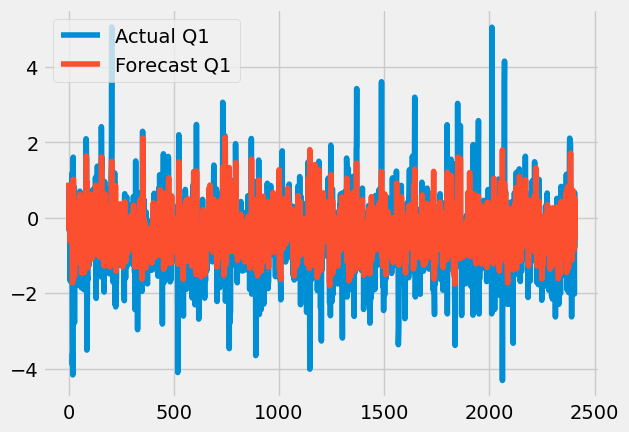

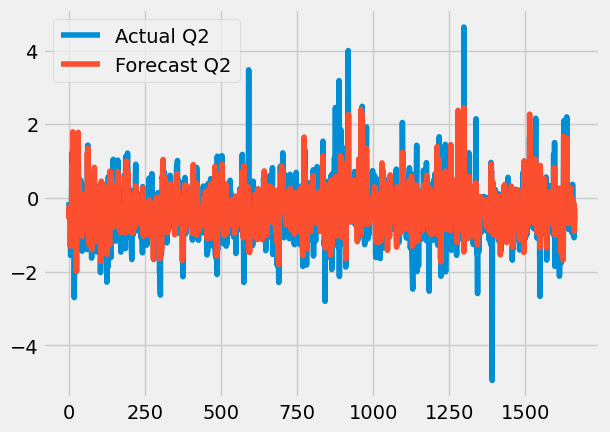

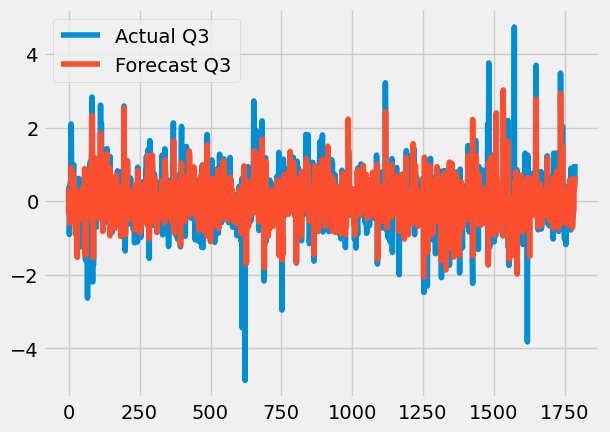

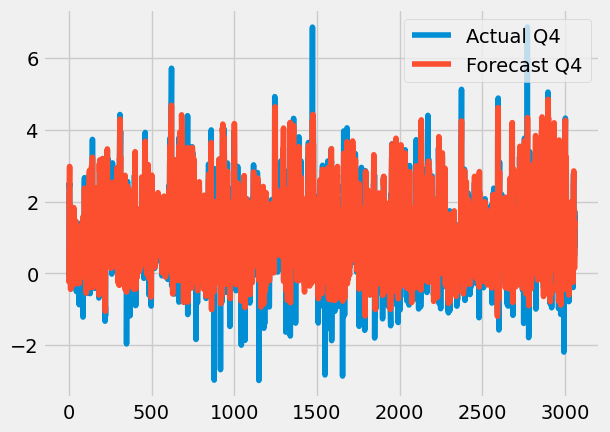

In [31]:
Q1_forecast = Q1_model.predict(Q1_X_test)
Q2_forecast = Q2_model.predict(Q2_X_test)
Q3_forecast = Q3_model.predict(Q3_X_test)
Q4_forecast = Q4_model.predict(Q4_X_test)

plt.plot(Q1_y_test.values, label='Actual Q1')
plt.plot(Q1_forecast, label='Forecast Q1')
plt.legend()
plt.show()

plt.plot(Q2_y_test.values, label='Actual Q2')
plt.plot(Q2_forecast, label='Forecast Q2')
plt.legend()
plt.show()

plt.plot(Q3_y_test.values, label='Actual Q3')
plt.plot(Q3_forecast, label='Forecast Q3')
plt.legend()
plt.show()

plt.plot(Q4_y_test.values, label='Actual Q4')
plt.plot(Q4_forecast, label='Forecast Q4')
plt.legend()
plt.show()

In [32]:
print("Housing_df:", sorted(Housing_df['Year'].unique()))
print("Q1_df:", sorted(Q1_df['Year'].unique()))
print("Q1_test:", sorted(Q1_test['Year'].unique()))

Housing_df: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2021), np.int64(2022)]
Q1_df: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2021)]
Q1_test: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2021)]


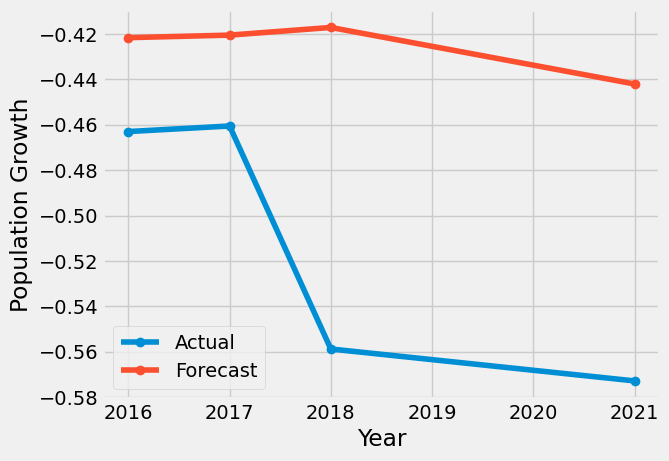

[2016 2017 2018 2021]


In [33]:
Q1_results = Q1_test[['Year']].copy()

Q1_results['Actual'] = Q1_y_test.values
Q1_results['Forecast'] = Q1_forecast

Q1_yearly = Q1_results.groupby('Year')[['Actual', 'Forecast']].mean()

Q1_yearly.plot(marker='o')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()

print(Q1_test['Year'].unique())

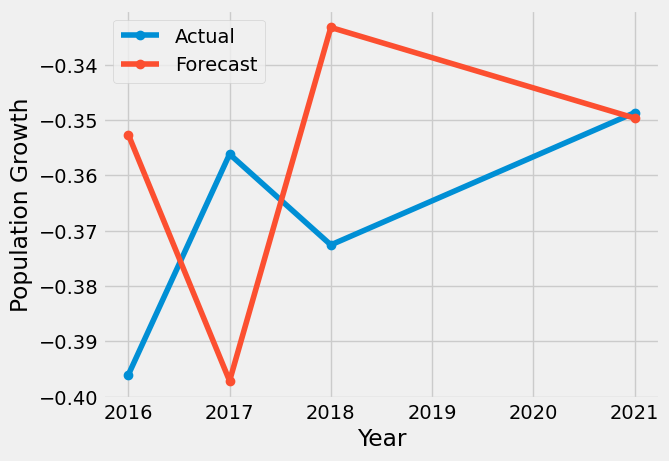

In [34]:
Q2_results = Q2_test[['Year']].copy()

Q2_results['Actual'] = Q2_y_test.values
Q2_results['Forecast'] = Q2_forecast

Q2_yearly = Q2_results.groupby('Year')[['Actual', 'Forecast']].mean()

Q2_yearly.plot(marker='o')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()

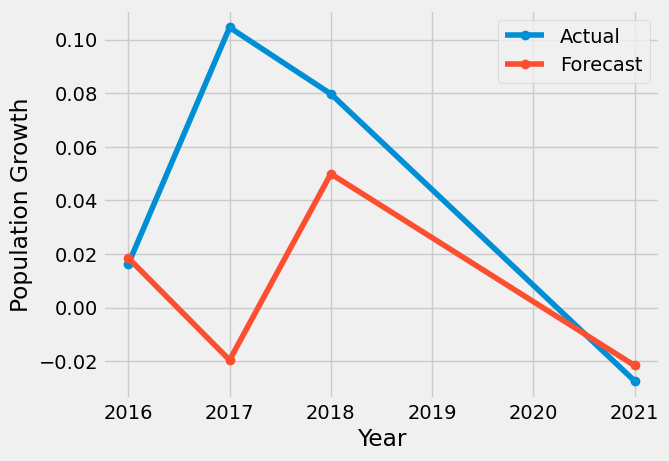

In [35]:
Q3_results = Q3_test[['Year']].copy()

Q3_results['Actual'] = Q3_y_test.values
Q3_results['Forecast'] = Q3_forecast

Q3_yearly = Q3_results.groupby('Year')[['Actual', 'Forecast']].mean()

Q3_yearly.plot(marker='o')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()

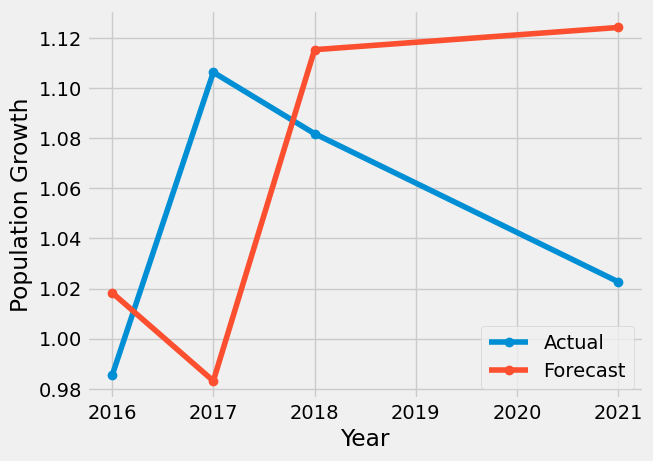

In [36]:
Q4_results = Q4_test[['Year']].copy()

Q4_results['Actual'] = Q4_y_test.values
Q4_results['Forecast'] = Q4_forecast

Q4_yearly = Q4_results.groupby('Year')[['Actual', 'Forecast']].mean()

Q4_yearly.plot(marker='o')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()

In [37]:
from sklearn.metrics import root_mean_squared_error

print("Q1 Test RMSE:", root_mean_squared_error(Q1_y_test, Q1_forecast))
print("Q2 Test RMSE:", root_mean_squared_error(Q2_y_test, Q2_forecast))
print("Q3 Test RMSE:", root_mean_squared_error(Q3_y_test, Q3_forecast))
print("Q4 Test RMSE:", root_mean_squared_error(Q4_y_test, Q4_forecast))

Q1 Test RMSE: 0.7055550872060808
Q2 Test RMSE: 0.5159036749310714
Q3 Test RMSE: 0.5330150124494936
Q4 Test RMSE: 0.5182310922777746


In [38]:
print("Q1 Actual vs Predicted:")
print(Q1_yearly)

print("\nQ2 Actual vs Predicted:")
print(Q2_yearly)

print("\nQ3 Actual vs Predicted:")
print(Q3_yearly)

print("\nQ4 Actual vs Predicted:")
print(Q4_yearly)

Q1 Actual vs Predicted:
        Actual  Forecast
Year                    
2016 -0.462991 -0.421634
2017 -0.460543 -0.420507
2018 -0.558785 -0.417132
2021 -0.572846 -0.442043

Q2 Actual vs Predicted:
        Actual  Forecast
Year                    
2016 -0.396021 -0.352629
2017 -0.356143 -0.397129
2018 -0.372547 -0.333245
2021 -0.348653 -0.349626

Q3 Actual vs Predicted:
        Actual  Forecast
Year                    
2016  0.016277  0.018464
2017  0.104570 -0.019629
2018  0.079754  0.049920
2021 -0.027411 -0.021650

Q4 Actual vs Predicted:
        Actual  Forecast
Year                    
2016  0.985332  1.018362
2017  1.106316  0.983153
2018  1.081828  1.115337
2021  1.022694  1.124211


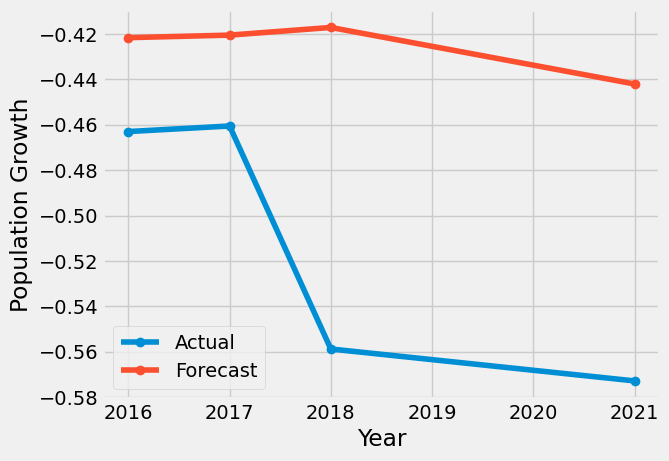

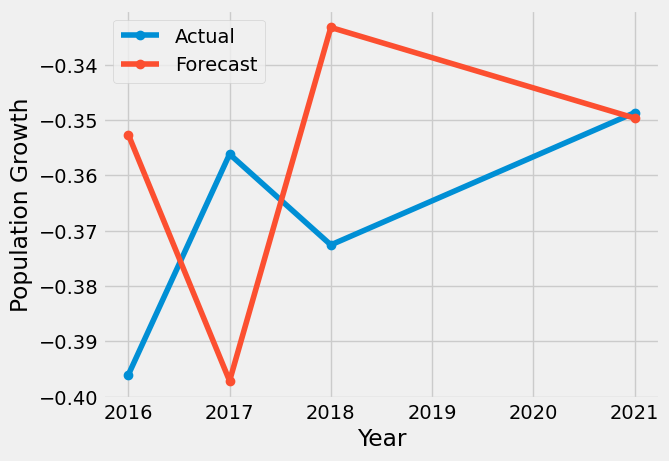

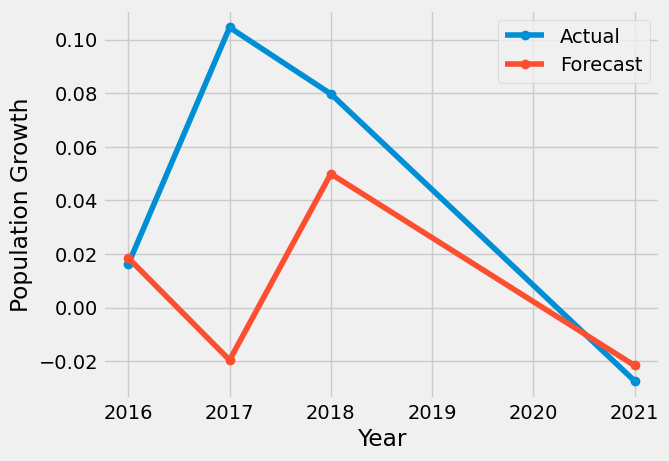

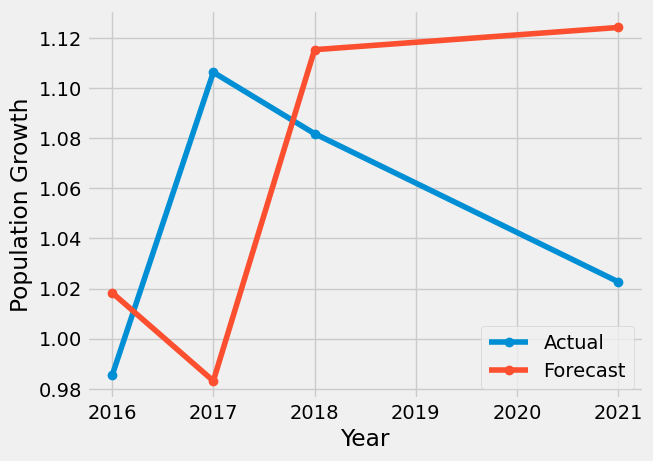

In [39]:
Q1_results = Q1_test[['Year']].copy()

Q1_results['Actual'] = Q1_y_test.values
Q1_results['Forecast'] = Q1_forecast

Q1_yearly = Q1_results.groupby('Year')[['Actual', 'Forecast']].mean()

Q1_yearly.plot(marker='o')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()




Q2_results = Q2_test[['Year']].copy()

Q2_results['Actual'] = Q2_y_test.values
Q2_results['Forecast'] = Q2_forecast

Q2_yearly = Q2_results.groupby('Year')[['Actual', 'Forecast']].mean()

Q2_yearly.plot(marker='o')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()




Q3_results = Q3_test[['Year']].copy()

Q3_results['Actual'] = Q3_y_test.values
Q3_results['Forecast'] = Q3_forecast

Q3_yearly = Q3_results.groupby('Year')[['Actual', 'Forecast']].mean()

Q3_yearly.plot(marker='o')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()




Q4_results = Q4_test[['Year']].copy()

Q4_results['Actual'] = Q4_y_test.values
Q4_results['Forecast'] = Q4_forecast

Q4_yearly = Q4_results.groupby('Year')[['Actual', 'Forecast']].mean()

Q4_yearly.plot(marker='o')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()

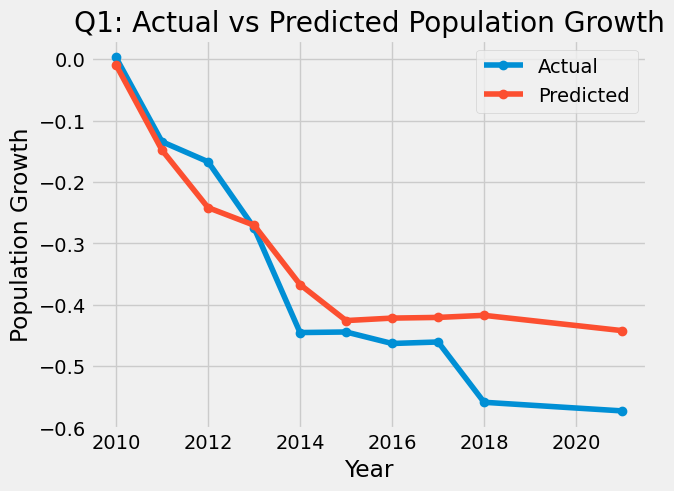

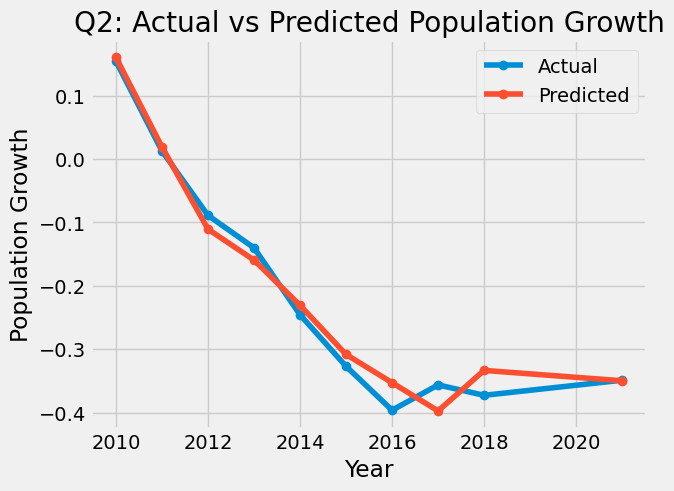

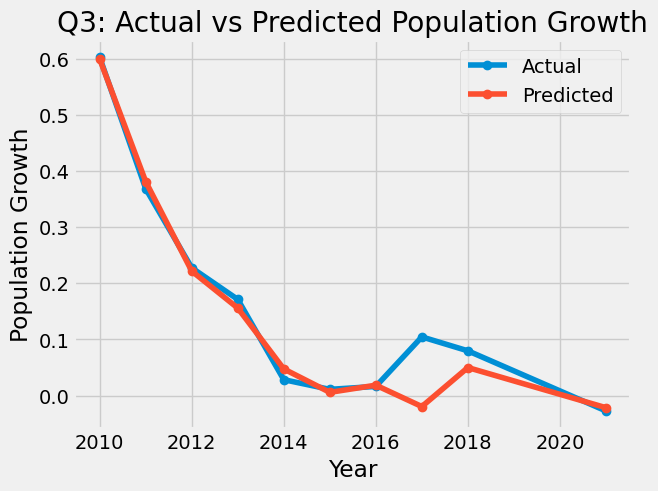

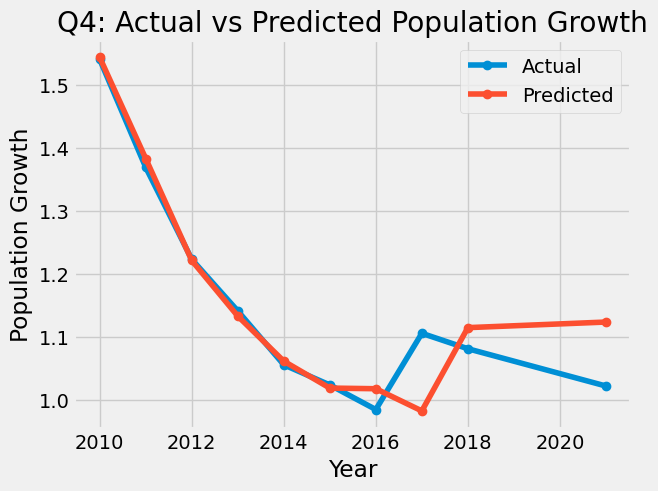

In [40]:
# Q1
Q1_results = Q1_df[['Year']].copy()
Q1_results['Actual'] = Q1_df['Corresponding_Population_Growth'].values
Q1_results['Predicted'] = Q1_model.predict(Q1_X)

Q1_yearly = Q1_results.groupby('Year')[['Actual', 'Predicted']].mean()

Q1_yearly.plot(marker='o')
plt.title('Q1: Actual vs Predicted Population Growth')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()



# Q2
Q2_results = Q2_df[['Year']].copy()
Q2_results['Actual'] = Q2_df['Corresponding_Population_Growth'].values
Q2_results['Predicted'] = Q2_model.predict(Q2_X)

Q2_yearly = Q2_results.groupby('Year')[['Actual', 'Predicted']].mean()

Q2_yearly.plot(marker='o')
plt.title('Q2: Actual vs Predicted Population Growth')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()


# Q3
Q3_results = Q3_df[['Year']].copy()
Q3_results['Actual'] = Q3_df['Corresponding_Population_Growth'].values
Q3_results['Predicted'] = Q3_model.predict(Q3_X)

Q3_yearly = Q3_results.groupby('Year')[['Actual', 'Predicted']].mean()

Q3_yearly.plot(marker='o')
plt.title('Q3: Actual vs Predicted Population Growth')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()


# Q4
Q4_results = Q4_df[['Year']].copy()
Q4_results['Actual'] = Q4_df['Corresponding_Population_Growth'].values
Q4_results['Predicted'] = Q4_model.predict(Q4_X)

Q4_yearly = Q4_results.groupby('Year')[['Actual', 'Predicted']].mean()

Q4_yearly.plot(marker='o')
plt.title('Q4: Actual vs Predicted Population Growth')
plt.xlabel('Year')
plt.ylabel('Population Growth')
plt.legend()
plt.show()


In [41]:
weighted_growth = (
    Housing_df.groupby('Year')
    .apply(lambda x: np.average(
        x['Corresponding_Population_Growth'],
        weights=x['Total_Population']
    ))
)

print(weighted_growth)

Year
2010    0.859365
2011    0.826160
2012    0.774281
2013    0.824791
2014    0.766519
2015    0.645496
2016    0.768765
2017    0.591595
2018    0.557258
2019    0.577415
2021    0.419966
2022    0.399259
dtype: float64


/var/folders/2m/nflhfs952mncjv1fykz_63vw0000gn/T/ipykernel_93011/3388099957.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: np.average(


In [42]:
weighted_growth = (
    Housing_df.dropna(
        subset=['Corresponding_Population_Growth', 'Total_Population']
    )
    .groupby('Year')
    .apply(lambda x: np.average(
        x['Corresponding_Population_Growth'],
        weights=x['Total_Population']
    ))
)

print(weighted_growth)

Year
2010    0.859365
2011    0.826160
2012    0.774281
2013    0.824791
2014    0.766519
2015    0.645496
2016    0.768765
2017    0.591595
2018    0.557258
2019    0.577415
2021    0.419966
2022    0.399259
dtype: float64


/var/folders/2m/nflhfs952mncjv1fykz_63vw0000gn/T/ipykernel_93011/3332265443.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: np.average(


In [ ]:
#ARIMA Continued

In [48]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(weighted_growth)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

ADF Statistic: 2.383329242798564
p-value: 0.9990022471772936


In [49]:
weighted_growth_diff = weighted_growth.diff().dropna()

adf_result_diff = adfuller(weighted_growth_diff)

print("ADF Statistic:", adf_result_diff[0])
print("p-value:", adf_result_diff[1])

ADF Statistic: -1.4507565582501292
p-value: 0.557715697929876


In [50]:
weighted_growth_diff2 = weighted_growth.diff().diff().dropna()

adf_result_diff2 = adfuller(weighted_growth_diff2)

print("ADF Statistic:", adf_result_diff2[0])
print("p-value:", adf_result_diff2[1])

ADF Statistic: -10.372134488588511
p-value: 2.249725792980634e-18


In [51]:
arima_results = arima_grid_search(
    weighted_growth,
    d=2
)

print(arima_results.head(10))

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a 

   p  d  q        AIC
0  5  2  4 -26.190666
1  3  2  0 -23.420564
2  4  2  0 -22.624915
3  3  2  1 -22.533006
4  2  2  0 -22.415487
5  3  2  3 -22.286838
6  2  2  1 -22.035078
7  4  2  1 -21.948159
8  3  2  2 -21.893039
9  5  2  1 -20.477766


/Users/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [52]:
overall_arima_model = ARIMA(
    weighted_growth,
    order=(5, 2, 3)
).fit()

print(overall_arima_model.summary())

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to 

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   12
Model:                 ARIMA(5, 2, 3)   Log Likelihood                  17.293
Date:                Tue, 20 Oct 2026   AIC                            -16.587
Time:                        00:22:45   BIC                            -13.864
Sample:                             0   HQIC                           -19.574
                                 - 12                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7203     75.675     -0.010      0.992    -149.041     147.600
ar.L2          0.5929     90.875      0.007      0.995    -177.519     178.705
ar.L3          1.0656      3.096      0.344      0.7

In [53]:
overall_forecast = overall_arima_model.get_forecast(steps=5)

overall_mean = overall_forecast.predicted_mean
overall_ci = overall_forecast.conf_int()

print("Forecast:")
print(overall_mean)

print("\n95% Confidence Interval:")
print(overall_ci)

Forecast:
12    0.406622
13    0.205114
14    0.269990
15    0.172900
16    0.057521
Name: predicted_mean, dtype: float64

95% Confidence Interval:
     lower y   upper y
12  0.352299  0.460945
13  0.144468  0.265760
14  0.180538  0.359442
15  0.034983  0.310817
16 -0.114931  0.229974


/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


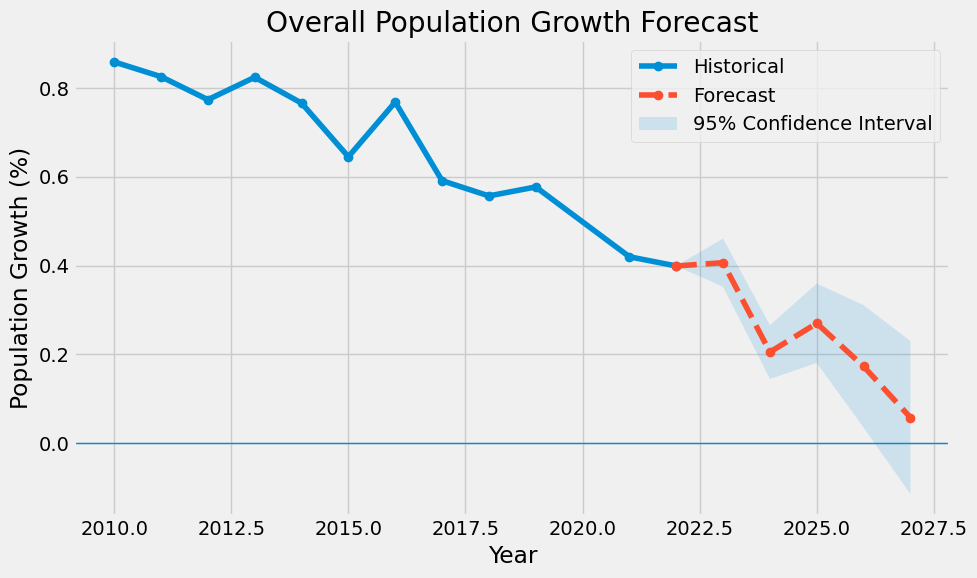

In [54]:
import matplotlib.pyplot as plt

overall_forecast = overall_arima_model.get_forecast(steps=5)

overall_mean = overall_forecast.predicted_mean
overall_ci = overall_forecast.conf_int()

last_year = weighted_growth.index[-1]
last_value = weighted_growth.iloc[-1]

forecast_years = range(
    last_year,
    last_year + 6
)

forecast_values = [last_value] + list(overall_mean)
ci_lower = [last_value] + list(overall_ci.iloc[:, 0])
ci_upper = [last_value] + list(overall_ci.iloc[:, 1])

plt.figure(figsize=(10, 6))

plt.plot(
    weighted_growth.index,
    weighted_growth.values,
    marker='o',
    label='Historical'
)

plt.plot(
    forecast_years,
    forecast_values,
    marker='o',
    linestyle='--',
    label='Forecast'
)

plt.fill_between(
    forecast_years,
    ci_lower,
    ci_upper,
    alpha=0.15,
    label='95% Confidence Interval'
)

plt.axhline(0, linewidth=1)

plt.title('Overall Population Growth Forecast')
plt.xlabel('Year')
plt.ylabel('Population Growth (%)')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [55]:
print(arima_results.head(10))

   p  d  q        AIC
0  5  2  4 -26.190666
1  3  2  0 -23.420564
2  4  2  0 -22.624915
3  3  2  1 -22.533006
4  2  2  0 -22.415487
5  3  2  3 -22.286838
6  2  2  1 -22.035078
7  4  2  1 -21.948159
8  3  2  2 -21.893039
9  5  2  1 -20.477766


In [56]:
overall_arima_model_320 = ARIMA(
    weighted_growth,
    order=(3, 2, 0)
).fit()

overall_forecast_320 = overall_arima_model_320.get_forecast(steps=5)

overall_mean_320 = overall_forecast_320.predicted_mean
overall_ci_320 = overall_forecast_320.conf_int()

print("Forecast:")
print(overall_mean_320)

print("\n95% Confidence Interval:")
print(overall_ci_320)




overall_arima_model_420 = ARIMA(
    weighted_growth,
    order=(4, 2, 0)
).fit()

overall_forecast_420 = overall_arima_model_420.get_forecast(steps=5)

print("\n\n\nARIMA(4,2,0) Forecast:")
print(overall_forecast_420.predicted_mean)

print("\n95% Confidence Interval:")
print(overall_forecast_420.conf_int())




overall_arima_model_220 = ARIMA(
    weighted_growth,
    order=(2, 2, 0)
).fit()

overall_forecast_220 = overall_arima_model_220.get_forecast(steps=5)

print("\n\n\nARIMA(2,2,0) Forecast:")
print(overall_forecast_220.predicted_mean)

print("\n95% Confidence Interval:")
print(overall_forecast_220.conf_int())

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


Forecast:
12    0.389644
13    0.243163
14    0.242389
15    0.197340
16    0.075046
Name: predicted_mean, dtype: float64

95% Confidence Interval:
     lower y   upper y
12  0.311528  0.467760
13  0.161758  0.324568
14  0.131495  0.353283
15  0.042346  0.352333
16 -0.098586  0.248677



ARIMA(4,2,0) Forecast:
12    0.406564
13    0.231526
14    0.260376
15    0.211821
16    0.066650
Name: predicted_mean, dtype: float64

95% Confidence Interval:
     lower y   upper y
12  0.339323  0.473805
13  0.152789  0.310264
14  0.133242  0.387510
15  0.027641  0.396000
16 -0.163469  0.296768



ARIMA(2,2,0) Forecast:
12    0.365634
13    0.229227
14    0.229465
15    0.152035
16    0.050933
Name: predicted_mean, dtype: float64

95% Confidence Interval:
     lower y   upper y
12  0.268726  0.462543
13  0.106355  0.352099
14  0.061503  0.397426
15 -0.095904  0.399974
16 -0.245605  0.347472


/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for for

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


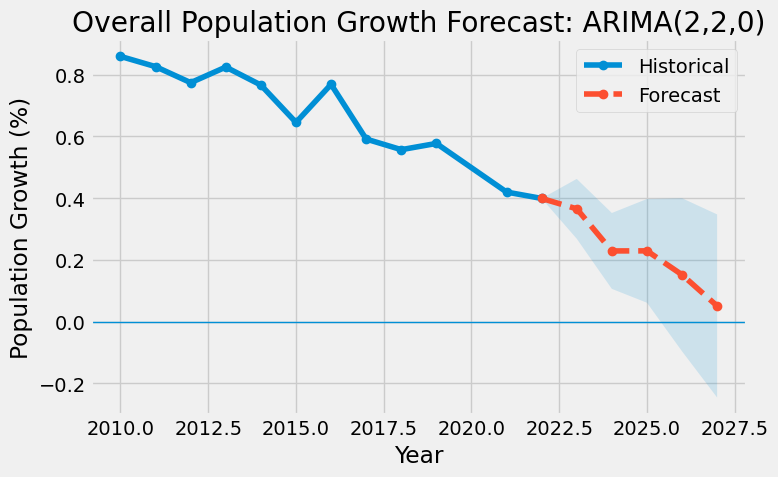

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


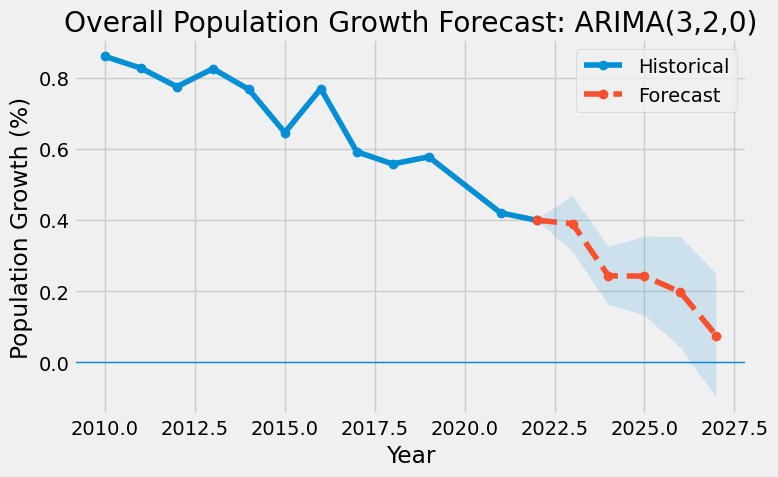

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


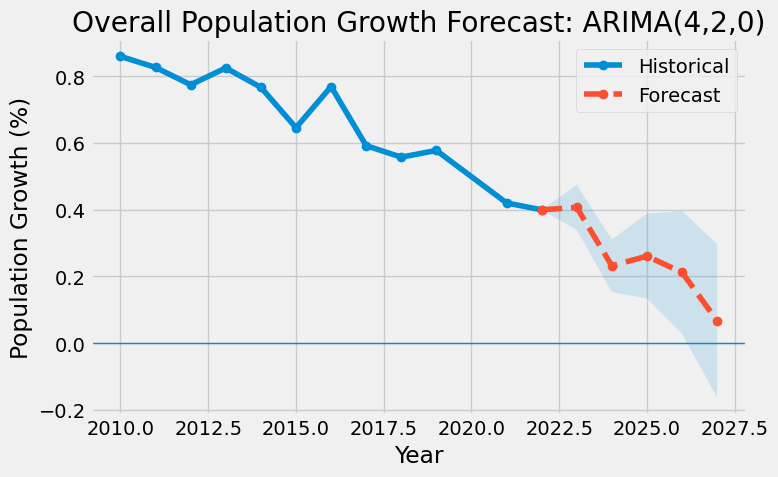

In [57]:
import matplotlib.pyplot as plt

models = {
    'ARIMA(2,2,0)': overall_arima_model_220,
    'ARIMA(3,2,0)': overall_arima_model_320,
    'ARIMA(4,2,0)': overall_arima_model_420
}

for name, model in models.items():

    forecast = model.get_forecast(steps=5)
    forecast_mean = forecast.predicted_mean
    forecast_ci = forecast.conf_int()

    forecast_years = range(
        weighted_growth.index[-1],
        weighted_growth.index[-1] + 6
    )

    forecast_values = [
        weighted_growth.iloc[-1]
    ] + list(forecast_mean)

    ci_lower = [
        weighted_growth.iloc[-1]
    ] + list(forecast_ci.iloc[:, 0])

    ci_upper = [
        weighted_growth.iloc[-1]
    ] + list(forecast_ci.iloc[:, 1])

    plt.figure(figsize=(8, 5))

    plt.plot(
        weighted_growth.index,
        weighted_growth.values,
        marker='o',
        label='Historical'
    )

    plt.plot(
        forecast_years,
        forecast_values,
        marker='o',
        linestyle='--',
        label='Forecast'
    )

    plt.fill_between(
        forecast_years,
        ci_lower,
        ci_upper,
        alpha=0.15
    )

    plt.axhline(0, linewidth=1)

    plt.title(f'Overall Population Growth Forecast: {name}')
    plt.xlabel('Year')
    plt.ylabel('Population Growth (%)')

    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [58]:
forecast_Q1 = Q1_arima_model.get_forecast(steps=5)
forecast_Q2 = Q2_arima_model.get_forecast(steps=5)
forecast_Q3 = Q3_arima_model.get_forecast(steps=5)
forecast_Q4 = Q4_arima_model.get_forecast(steps=5)

print("Q1 Forecast:")
print(forecast_Q1.predicted_mean)

print("\nQ2 Forecast:")
print(forecast_Q2.predicted_mean)

print("\nQ3 Forecast:")
print(forecast_Q3.predicted_mean)

print("\nQ4 Forecast:")
print(forecast_Q4.predicted_mean)

Q1 Forecast:
10   -0.555559
11   -0.519629
12   -0.467847
13   -0.403915
14   -0.332180
Name: predicted_mean, dtype: float64

Q2 Forecast:
10   -0.323304
11   -0.198801
12   -0.120848
13   -0.022031
14    0.058238
Name: predicted_mean, dtype: float64

Q3 Forecast:
10   -0.070516
11   -0.065160
12   -0.027234
13    0.028879
14    0.091380
Name: predicted_mean, dtype: float64

Q4 Forecast:
10    1.011220
11    1.031563
12    1.069626
13    1.114199
14    1.157318
Name: predicted_mean, dtype: float64


/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


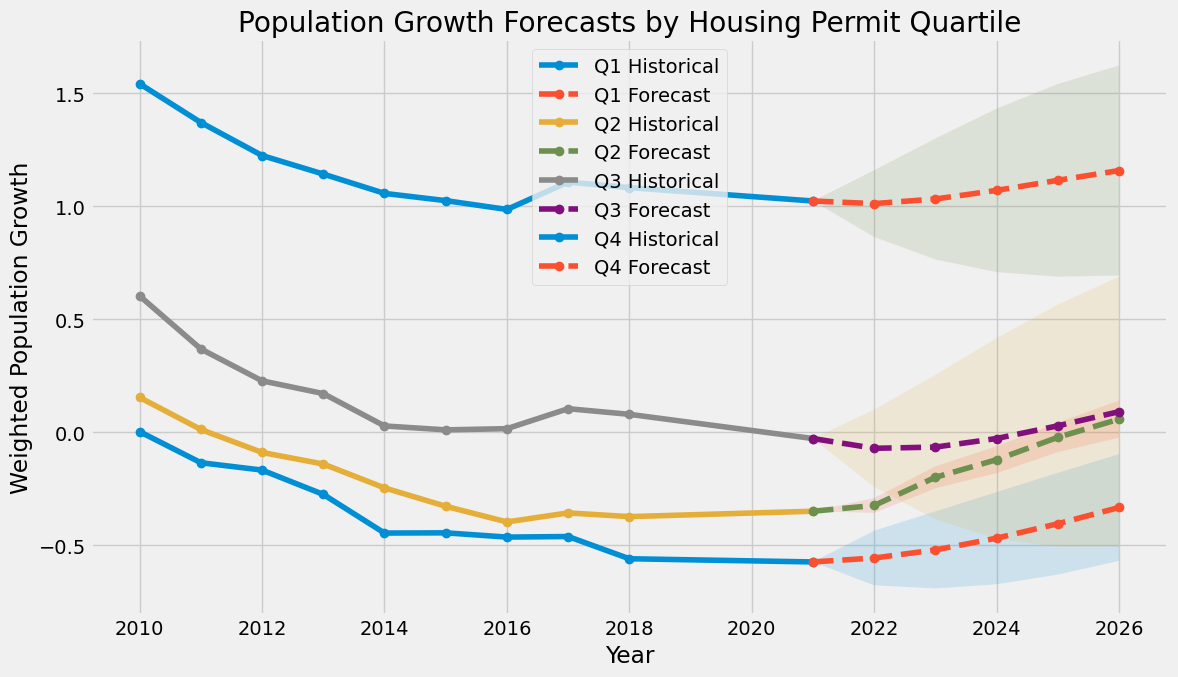

In [59]:
import matplotlib.pyplot as plt

# Get forecasts and confidence intervals
forecast_Q1 = Q1_arima_model.get_forecast(steps=5)
forecast_Q2 = Q2_arima_model.get_forecast(steps=5)
forecast_Q3 = Q3_arima_model.get_forecast(steps=5)
forecast_Q4 = Q4_arima_model.get_forecast(steps=5)

# Get confidence intervals
ci_Q1 = forecast_Q1.conf_int()
ci_Q2 = forecast_Q2.conf_int()
ci_Q3 = forecast_Q3.conf_int()
ci_Q4 = forecast_Q4.conf_int()

plt.figure(figsize=(12, 7))

# Q1
plt.plot(
    Q1_arima_data.index,
    Q1_arima_data.values,
    marker='o',
    label='Q1 Historical'
)

forecast_years_Q1 = range(
    Q1_arima_data.index[-1],
    Q1_arima_data.index[-1] + 6
)

plt.plot(
    forecast_years_Q1,
    [Q1_arima_data.iloc[-1]] + list(forecast_Q1.predicted_mean),
    marker='o',
    linestyle='--',
    label='Q1 Forecast'
)

plt.fill_between(
    forecast_years_Q1,
    [Q1_arima_data.iloc[-1]] + list(ci_Q1.iloc[:, 0]),
    [Q1_arima_data.iloc[-1]] + list(ci_Q1.iloc[:, 1]),
    alpha=0.15
)


# Q2
plt.plot(
    Q2_arima_data.index,
    Q2_arima_data.values,
    marker='o',
    label='Q2 Historical'
)

forecast_years_Q2 = range(
    Q2_arima_data.index[-1],
    Q2_arima_data.index[-1] + 6
)

plt.plot(
    forecast_years_Q2,
    [Q2_arima_data.iloc[-1]] + list(forecast_Q2.predicted_mean),
    marker='o',
    linestyle='--',
    label='Q2 Forecast'
)

plt.fill_between(
    forecast_years_Q2,
    [Q2_arima_data.iloc[-1]] + list(ci_Q2.iloc[:, 0]),
    [Q2_arima_data.iloc[-1]] + list(ci_Q2.iloc[:, 1]),
    alpha=0.15
)


# Q3
plt.plot(
    Q3_arima_data.index,
    Q3_arima_data.values,
    marker='o',
    label='Q3 Historical'
)

forecast_years_Q3 = range(
    Q3_arima_data.index[-1],
    Q3_arima_data.index[-1] + 6
)

plt.plot(
    forecast_years_Q3,
    [Q3_arima_data.iloc[-1]] + list(forecast_Q3.predicted_mean),
    marker='o',
    linestyle='--',
    label='Q3 Forecast'
)

plt.fill_between(
    forecast_years_Q3,
    [Q3_arima_data.iloc[-1]] + list(ci_Q3.iloc[:, 0]),
    [Q3_arima_data.iloc[-1]] + list(ci_Q3.iloc[:, 1]),
    alpha=0.15
)


# Q4
plt.plot(
    Q4_arima_data.index,
    Q4_arima_data.values,
    marker='o',
    label='Q4 Historical'
)

forecast_years_Q4 = range(
    Q4_arima_data.index[-1],
    Q4_arima_data.index[-1] + 6
)

plt.plot(
    forecast_years_Q4,
    [Q4_arima_data.iloc[-1]] + list(forecast_Q4.predicted_mean),
    marker='o',
    linestyle='--',
    label='Q4 Forecast'
)

plt.fill_between(
    forecast_years_Q4,
    [Q4_arima_data.iloc[-1]] + list(ci_Q4.iloc[:, 0]),
    [Q4_arima_data.iloc[-1]] + list(ci_Q4.iloc[:, 1]),
    alpha=0.15
)


plt.title(
    'Population Growth Forecasts by Housing Permit Quartile'
)

plt.xlabel('Year')
plt.ylabel('Weighted Population Growth')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


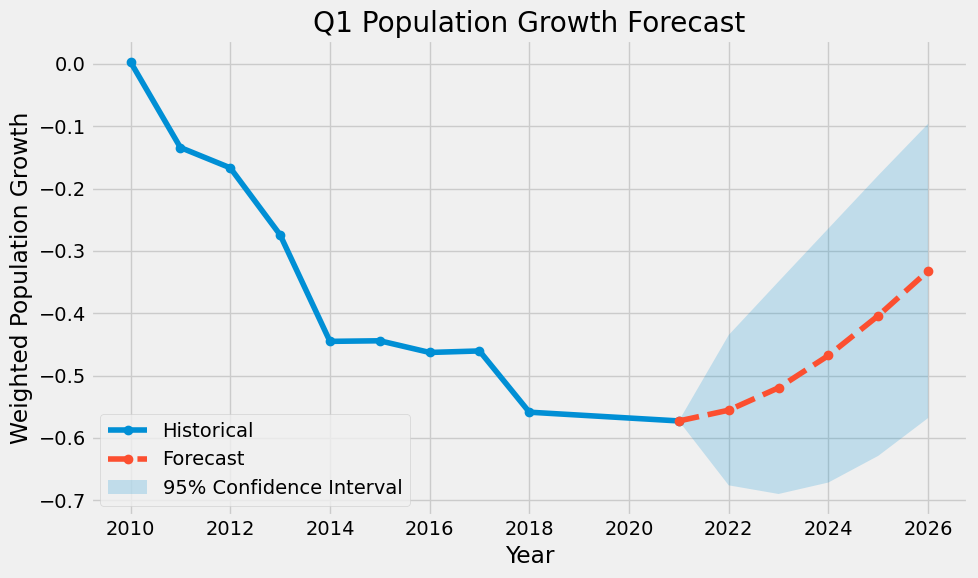

In [60]:
import matplotlib.pyplot as plt

forecast_Q1 = Q1_arima_model.get_forecast(steps=5)

forecast_mean = forecast_Q1.predicted_mean
forecast_ci = forecast_Q1.conf_int()

last_year = Q1_arima_data.index[-1]
last_value = Q1_arima_data.iloc[-1]

forecast_years = range(
    last_year,
    last_year + 6
)

# Include the last historical observation so the forecast connects to it
forecast_values = [last_value] + list(forecast_mean)

# Confidence interval starts at the first forecast year
ci_lower = [last_value] + list(forecast_ci.iloc[:, 0])
ci_upper = [last_value] + list(forecast_ci.iloc[:, 1])

plt.figure(figsize=(10, 6))

# Historical
plt.plot(
    Q1_arima_data.index,
    Q1_arima_data.values,
    marker='o',
    label='Historical'
)

# Forecast
plt.plot(
    forecast_years,
    forecast_values,
    marker='o',
    linestyle='--',
    label='Forecast'
)

# Confidence interval
plt.fill_between(
    forecast_years,
    ci_lower,
    ci_upper,
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title('Q1 Population Growth Forecast')
plt.xlabel('Year')
plt.ylabel('Weighted Population Growth')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


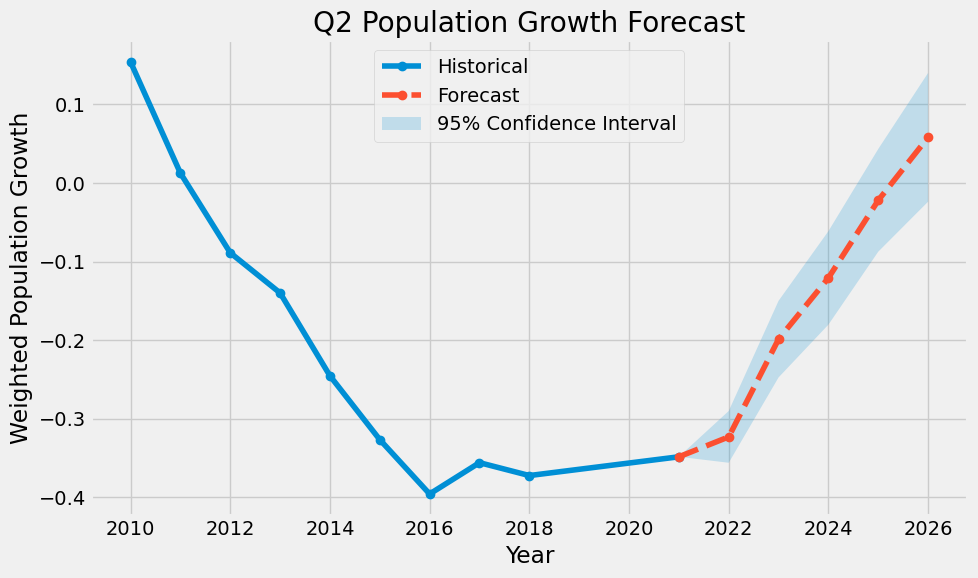

In [61]:
import matplotlib.pyplot as plt

forecast_Q2 = Q2_arima_model.get_forecast(steps=5)

forecast_mean = forecast_Q2.predicted_mean
forecast_ci = forecast_Q2.conf_int()

last_year = Q2_arima_data.index[-1]
last_value = Q2_arima_data.iloc[-1]

forecast_years = range(
    last_year,
    last_year + 6
)

# Include the last historical observation so the forecast connects to it
forecast_values = [last_value] + list(forecast_mean)

# Confidence interval starts at the last historical observation
ci_lower = [last_value] + list(forecast_ci.iloc[:, 0])
ci_upper = [last_value] + list(forecast_ci.iloc[:, 1])

plt.figure(figsize=(10, 6))

# Historical
plt.plot(
    Q2_arima_data.index,
    Q2_arima_data.values,
    marker='o',
    label='Historical'
)

# Forecast
plt.plot(
    forecast_years,
    forecast_values,
    marker='o',
    linestyle='--',
    label='Forecast'
)

# Confidence interval
plt.fill_between(
    forecast_years,
    ci_lower,
    ci_upper,
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title('Q2 Population Growth Forecast')
plt.xlabel('Year')
plt.ylabel('Weighted Population Growth')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


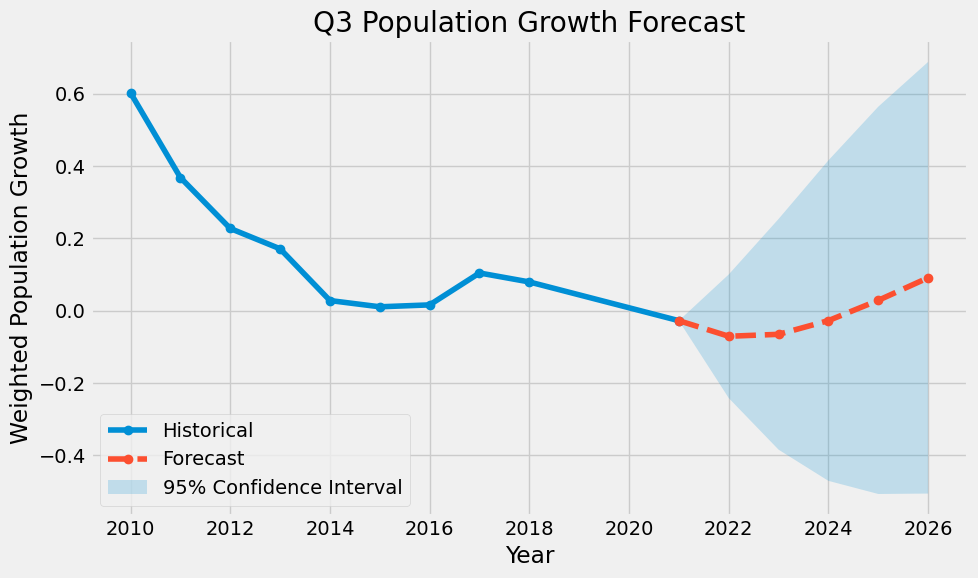

In [62]:
import matplotlib.pyplot as plt

forecast_Q3 = Q3_arima_model.get_forecast(steps=5)

forecast_mean = forecast_Q3.predicted_mean
forecast_ci = forecast_Q3.conf_int()

last_year = Q3_arima_data.index[-1]
last_value = Q3_arima_data.iloc[-1]

forecast_years = range(
    last_year,
    last_year + 6
)

# Include the last historical observation so the forecast connects to it
forecast_values = [last_value] + list(forecast_mean)

# Confidence interval starts at the last historical observation
ci_lower = [last_value] + list(forecast_ci.iloc[:, 0])
ci_upper = [last_value] + list(forecast_ci.iloc[:, 1])

plt.figure(figsize=(10, 6))

# Historical
plt.plot(
    Q3_arima_data.index,
    Q3_arima_data.values,
    marker='o',
    label='Historical'
)

# Forecast
plt.plot(
    forecast_years,
    forecast_values,
    marker='o',
    linestyle='--',
    label='Forecast'
)

# Confidence interval
plt.fill_between(
    forecast_years,
    ci_lower,
    ci_upper,
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title('Q3 Population Growth Forecast')
plt.xlabel('Year')
plt.ylabel('Weighted Population Growth')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

/Users/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


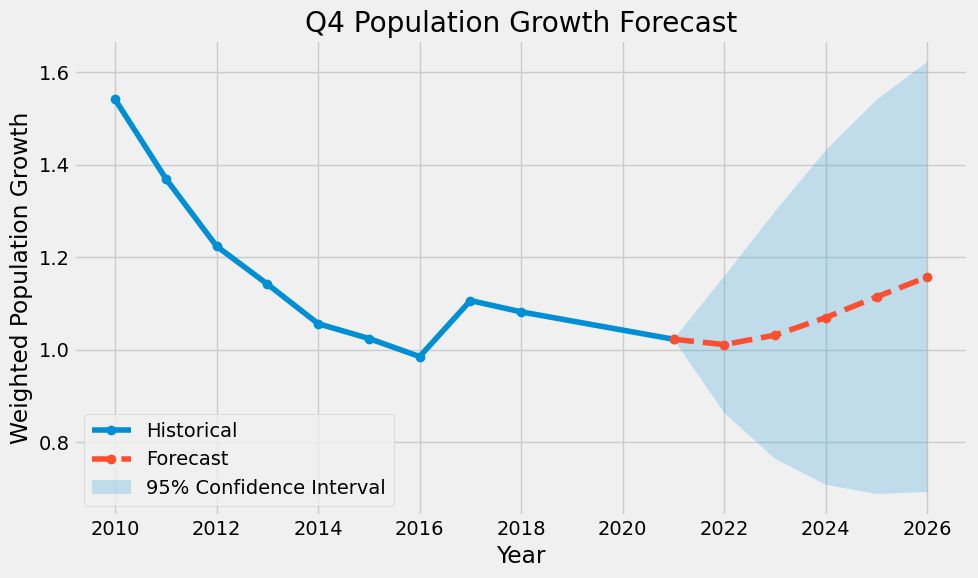

In [63]:
import matplotlib.pyplot as plt

forecast_Q4 = Q4_arima_model.get_forecast(steps=5)

forecast_mean = forecast_Q4.predicted_mean
forecast_ci = forecast_Q4.conf_int()

last_year = Q4_arima_data.index[-1]
last_value = Q4_arima_data.iloc[-1]

forecast_years = range(
    last_year,
    last_year + 6
)

# Include the last historical observation so the forecast connects to it
forecast_values = [last_value] + list(forecast_mean)

# Confidence interval starts at the last historical observation
ci_lower = [last_value] + list(forecast_ci.iloc[:, 0])
ci_upper = [last_value] + list(forecast_ci.iloc[:, 1])

plt.figure(figsize=(10, 6))

# Historical
plt.plot(
    Q4_arima_data.index,
    Q4_arima_data.values,
    marker='o',
    label='Historical'
)

# Forecast
plt.plot(
    forecast_years,
    forecast_values,
    marker='o',
    linestyle='--',
    label='Forecast'
)

# Confidence interval
plt.fill_between(
    forecast_years,
    ci_lower,
    ci_upper,
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title('Q4 Population Growth Forecast')
plt.xlabel('Year')
plt.ylabel('Weighted Population Growth')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [69]:
import pandas as pd

# Combine yearly actual and predicted values for all quartiles
xgboost_export = pd.concat([
    Q1_yearly.assign(Quartile="Q1"),
    Q2_yearly.assign(Quartile="Q2"),
    Q3_yearly.assign(Quartile="Q3"),
    Q4_yearly.assign(Quartile="Q4")
]).reset_index()

# Arrange columns
xgboost_export = xgboost_export[
    ["Year", "Quartile", "Actual", "Predicted"]
].sort_values(
    ["Quartile", "Year"]
).reset_index(drop=True)

In [70]:
xgboost_export

,Year,Quartile,Actual,Predicted
0,2010,Q1,0.003063,-0.008805
1,2011,Q1,-0.134243,-0.147877
2,2012,Q1,-0.166829,-0.241576
3,2013,Q1,-0.274251,-0.270265
4,2014,Q1,-0.445183,-0.366950
5,2015,Q1,-0.444248,-0.425653
6,2016,Q1,-0.462991,-0.421634
7,2017,Q1,-0.460543,-0.420507
8,2018,Q1,-0.558785,-0.417132
9,2021,Q1,-0.572846,-0.442043


In [72]:
import pandas as pd
import numpy as np

# Store each quartile's existing ARIMA results
arima_objects = [
    ("Q1", Q1_arima_data, forecast_Q1, ci_Q1),
    ("Q2", Q2_arima_data, forecast_Q2, ci_Q2),
    ("Q3", Q3_arima_data, forecast_Q3, ci_Q3),
    ("Q4", Q4_arima_data, forecast_Q4, ci_Q4)
]

arima_tables = []

for quartile, historical, forecast, ci in arima_objects:

    # Historical values
    historical_df = pd.DataFrame({
        "Year": historical.index,
        "Quartile": quartile,
        "Actual": historical.values,
        "Forecast": np.nan,
        "Lower_CI": np.nan,
        "Upper_CI": np.nan
    })

    # Forecast years: five years after the last historical year
    last_year = int(historical.index[-1])
    forecast_years = range(
        last_year + 1,
        last_year + len(forecast.predicted_mean) + 1
    )

    # Forecasts and confidence bounds
    forecast_df = pd.DataFrame({
        "Year": forecast_years,
        "Quartile": quartile,
        "Actual": np.nan,
        "Forecast": np.asarray(forecast.predicted_mean),
        "Lower_CI": ci.iloc[:, 0].to_numpy(),
        "Upper_CI": ci.iloc[:, 1].to_numpy()
    })

    arima_tables.extend([historical_df, forecast_df])

# Combine all quartiles
arima_export = pd.concat(
    arima_tables,
    ignore_index=True
).sort_values(
    ["Quartile", "Year"]
).reset_index(drop=True)

In [73]:
arima_export

,Year,Quartile,Actual,Forecast,Lower_CI,Upper_CI
0,2010,Q1,0.003063,NaN,NaN,NaN
1,2011,Q1,-0.134243,NaN,NaN,NaN
2,2012,Q1,-0.166829,NaN,NaN,NaN
3,2013,Q1,-0.274251,NaN,NaN,NaN
4,2014,Q1,-0.445183,NaN,NaN,NaN
5,2015,Q1,-0.444248,NaN,NaN,NaN
6,2016,Q1,-0.462991,NaN,NaN,NaN
7,2017,Q1,-0.460543,NaN,NaN,NaN
8,2018,Q1,-0.558785,NaN,NaN,NaN
9,2021,Q1,-0.572846,NaN,NaN,NaN


In [77]:
from pathlib import Path

output_folder = Path.home() / "Downloads"
output_folder.mkdir(parents=True, exist_ok=True)

# Export to Downloads
xgboost_export.to_excel(
    output_folder / "XGBoost_Actual_vs_Predicted.xlsx",
    index=False
)

arima_export.to_excel(
    output_folder / "ARIMA_Forecasts_with_CI.xlsx",
    index=False
)

print("Saved files to:", output_folder)
print("Exported files:")
print((output_folder / "XGBoost_Actual_vs_Predicted.xlsx").exists())
print((output_folder / "ARIMA_Forecasts_with_CI.xlsx").exists())

Saved files to: /Users/keyan/Downloads
Exported files:
True
True
